In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.colors import LogNorm

OUTROOT = "/work/hdd/bdne/nchartier/Q_correction"
NREAL = 50
N_ITER = 3
figroot = "Figures"
os.makedirs(figroot, exist_ok=True)

basedir = "."

QUIJOTE_ROOT = "/work/hdd/bdne/nchartier/quijote_lh"
CORR_ROOT = "/work/hdd/bdne/nchartier/Corr_correction"
QROOT = "/work/hdd/bdne/nchartier/Q_correction"

In [9]:
def compute_reduced_bispectrum(bk, ks, k_pk, pk):
    '''Q(k1,k2,k3) = B(k1,k2,k3) / [P(k1)P(k2)+P(k2)P(k3)+P(k3)P(k1)]'''
    k1, k2, k3 = ks[0], ks[1], ks[2]
    P1 = np.interp(k1, k_pk, pk)
    P2 = np.interp(k2, k_pk, pk)
    P3 = np.interp(k3, k_pk, pk)
    denom = P1 * P2 + P2 * P3 + P3 * P1
    return bk / denom


def load_all_cosmo_params(quijote_root, n_seeds=50):
    params = ["Omega_m", "Omega_b", "h", "n_s", "sigma_8"]
    arrs = {p: np.full(n_seeds, np.nan) for p in params}
    for seed in range(n_seeds):
        vals = np.loadtxt(os.path.join(quijote_root, str(seed), "Cosmo_params.dat"))
        for p, v in zip(params, vals):
            arrs[p][seed] = v
    return arrs

cosmo_params = load_all_cosmo_params(QUIJOTE_ROOT, n_seeds=50)

# After Q-corrections

In [11]:


def load_pk_ratio_Q(qroot, quijote_root, sim, seed, which):
    '''which: "pm" for the uncorrected baseline, or an iteration number (1,2,3).'''
    d = os.path.join(qroot, sim, "seed%d" % seed)
    if which == "pm":
        k = np.load(os.path.join(d, "k_pm_grid512.npy"))     # renamed -- was k_pm.npy
        pk = np.load(os.path.join(d, "pk_pm_grid512.npy"))   # renamed -- was pk_pm.npy
    else:
        it = int(which)
        k = np.load(os.path.join(d, "k_corrected_it%d.npy" % it))     # unchanged
        pk = np.load(os.path.join(d, "pk_corrected_it%d.npy" % it))   # unchanged

    nb_dir = os.path.join(quijote_root, str(seed))
    k_nb_ = np.load(os.path.join(nb_dir, "k.npy"))
    pk_nb_ = np.load(os.path.join(nb_dir, "pk.npy"))
    pk_nb_i = np.interp(k, k_nb_, pk_nb_)
    return k, pk / pk_nb_i


def plot_pk_ratio_grid_Q(qroot, quijote_root, sim, n_seeds=50, figroot=None, cmap_name="viridis",
                           color_by="seed", cosmo_params=None):
    if color_by != "seed" and cosmo_params is None:
        raise ValueError("cosmo_params must be provided when color_by is not 'seed'")

    stages = ["pm", "1", "2", "3"]
    titles = ["stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"]
    color_vals = np.arange(n_seeds) if color_by == "seed" else cosmo_params[color_by]
    cbar_label = "seed" if color_by == "seed" else color_by

    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=False, constrained_layout=True)
    axes = axes.ravel()
    cmap = plt.get_cmap(cmap_name)
    norm = plt.Normalize(vmin=np.nanmin(color_vals), vmax=np.nanmax(color_vals))

    for ax, stage, title in zip(axes, stages, titles):
        for seed in range(n_seeds):
            k, ratio = load_pk_ratio_Q(qroot, quijote_root, sim, seed, stage)
            ax.plot(k, ratio, color=cmap(norm(color_vals[seed])), alpha=0.8, lw=0.8)
        ax.axhline(1.0, color="white", lw=1, ls=":")
        ax.set_xscale("log")
        ax.set_title(title, fontsize=14)
        ax.grid(color="grey", alpha=0.3)
        ax.tick_params(labelsize = 14)

    for ax in axes[2:]:
        ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$", fontsize=15)
    for ax in axes[::2]:
        ax.set_ylabel(r"$P(k)/P_\mathrm{target}(k)$", fontsize=15)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes.tolist(), pad=0.02, aspect=40)
    cbar.set_label(cbar_label, fontsize=14)
    fig.suptitle(r"%s Q-case correction  ($N=%d$ seeds)" % (sim, n_seeds), fontsize=18, weight = "semibold")
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, f"pk_ratio_grid_Q_{sim}_by{color_by}.pdf"), bbox_inches="tight")

    return fig, axes

def plot_pk_ratio_envelope_Q(qroot, quijote_root, sim, n_seeds=50, figroot=None):
    stages = ["pm", "1", "2", "3"]
    labels = ["stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"]
    colors = ["tab:red", "tab:orange", "tab:green", "tab:blue"]

    fig, ax = plt.subplots(figsize=(9, 7))
    k_ref = None

    for stage, label, color in zip(stages, labels, colors):
        ratios = []
        for seed in range(n_seeds):
            try:
                k, ratio = load_pk_ratio_Q(qroot, quijote_root, sim, seed, stage)
            except FileNotFoundError:
                continue
            if k_ref is None:
                k_ref = k
            ratios.append(np.interp(k_ref, k, ratio))
        ratios = np.stack(ratios)

        median = np.median(ratios, axis=0)
        lo, hi = ratios.min(axis=0), ratios.max(axis=0)

        ax.plot(k_ref, median, color=color, lw=1.8, label=label)
        ax.fill_between(k_ref, lo, hi, color=color, alpha=0.2)

    ax.axhline(1.0, color="grey", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$", fontsize=16)
    ax.set_ylabel(r"$P(k)/P_\mathrm{target}(k)$", fontsize=16)
    ax.set_title(f"{sim} Q-case correction ($N={n_seeds}$ seeds, median + min/max envelope)", fontsize=13)
    ax.legend(fontsize=14)
    ax.grid(color="grey", alpha=0.3)
    ax.tick_params(labelsize = 14)
    plt.tight_layout()
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, f"pk_ratio_envelope_Q_{sim}.pdf"), bbox_inches="tight")
    return fig, ax

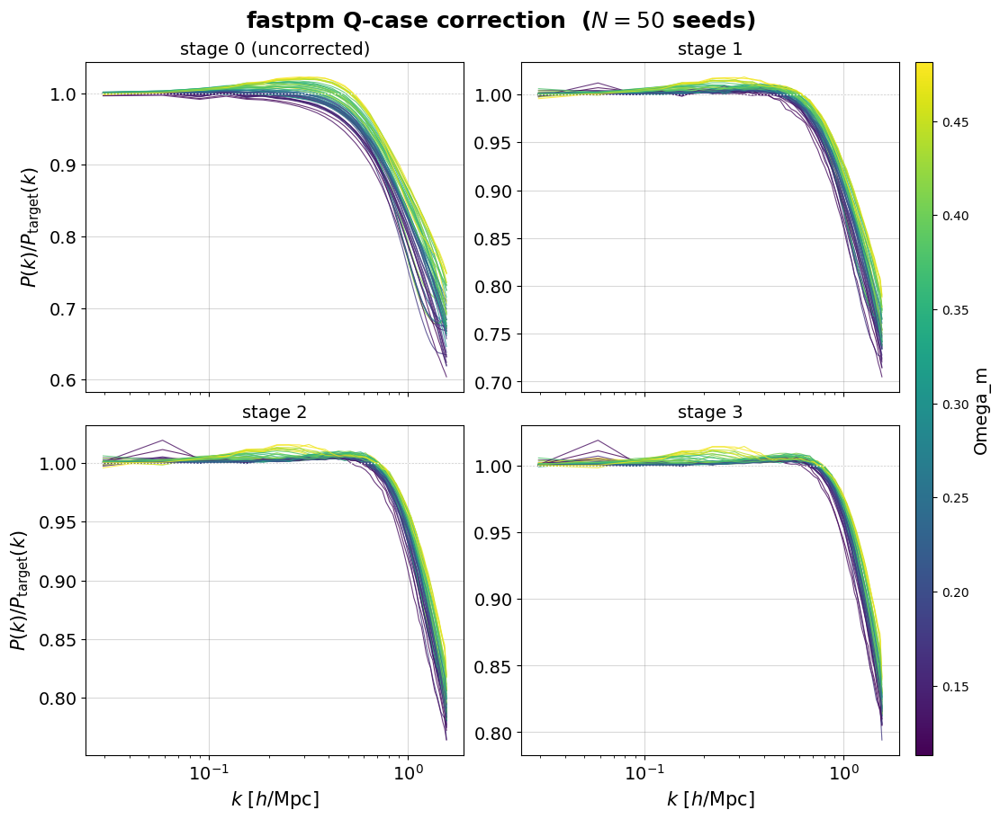

In [12]:
fig, axes = plot_pk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "fastpm", figroot=os.path.join(basedir, "FASTPM"), color_by="Omega_m", cosmo_params=cosmo_params)


(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'fastpm Q-case correction ($N=50$ seeds, median + min/max envelope)'}, xlabel='$k\\ [h/\\mathrm{Mpc}]$', ylabel='$P(k)/P_\\mathrm{target}(k)$'>)

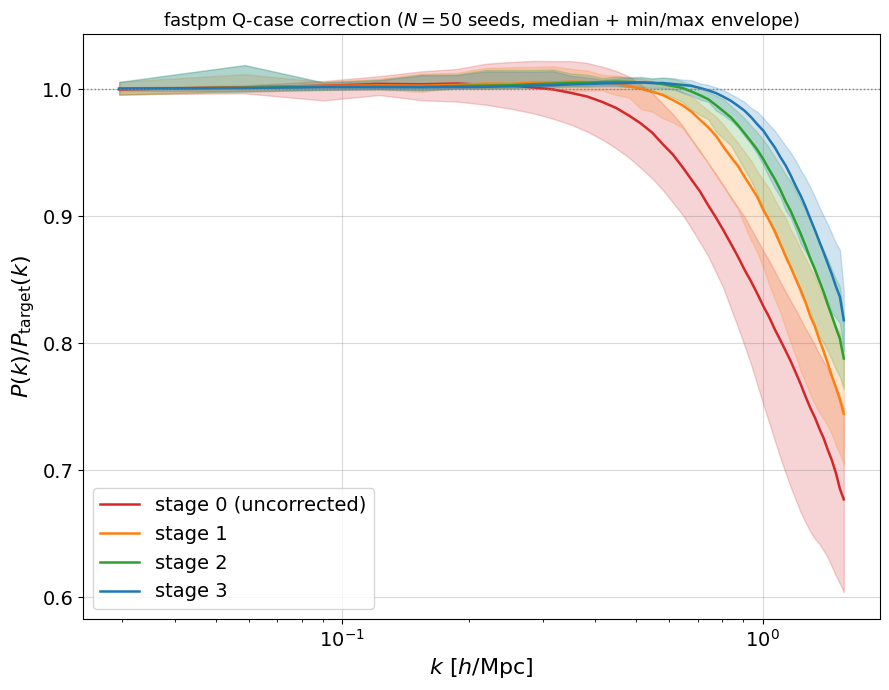

In [13]:
plot_pk_ratio_envelope_Q(QROOT, QUIJOTE_ROOT, "fastpm",figroot=os.path.join(basedir, "FASTPM"))

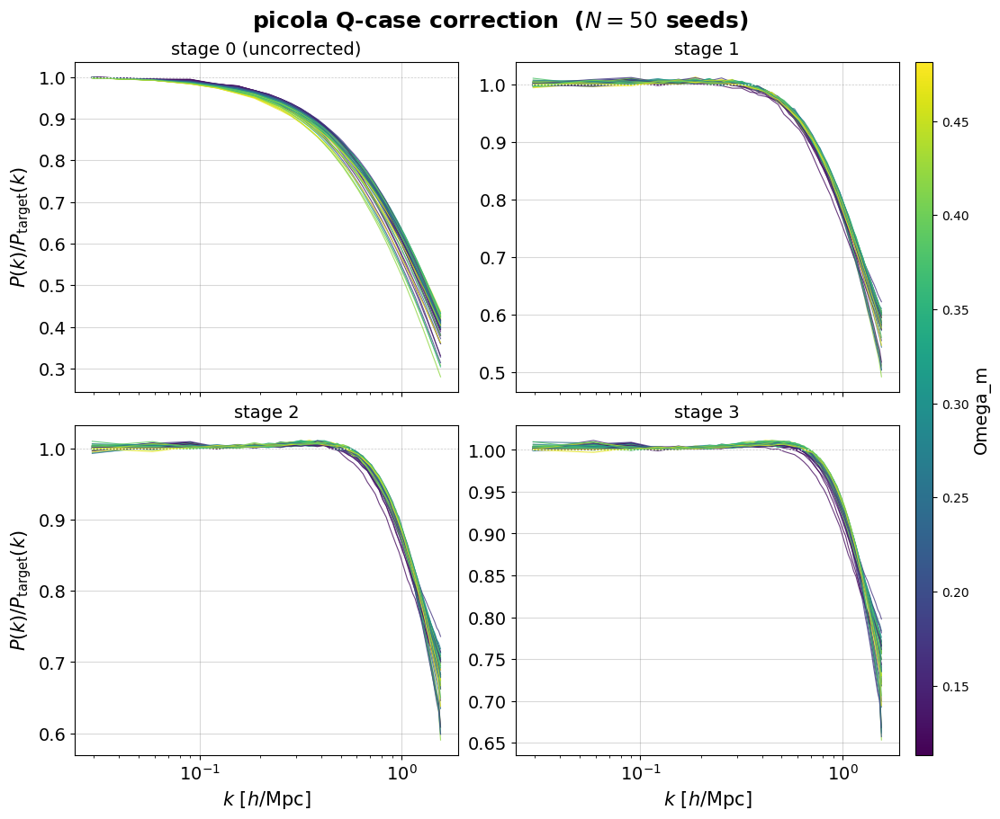

In [14]:
fig, axes = plot_pk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "picola", figroot=os.path.join(basedir, "PICOLA"), color_by="Omega_m", cosmo_params=cosmo_params)


(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'picola Q-case correction ($N=50$ seeds, median + min/max envelope)'}, xlabel='$k\\ [h/\\mathrm{Mpc}]$', ylabel='$P(k)/P_\\mathrm{target}(k)$'>)

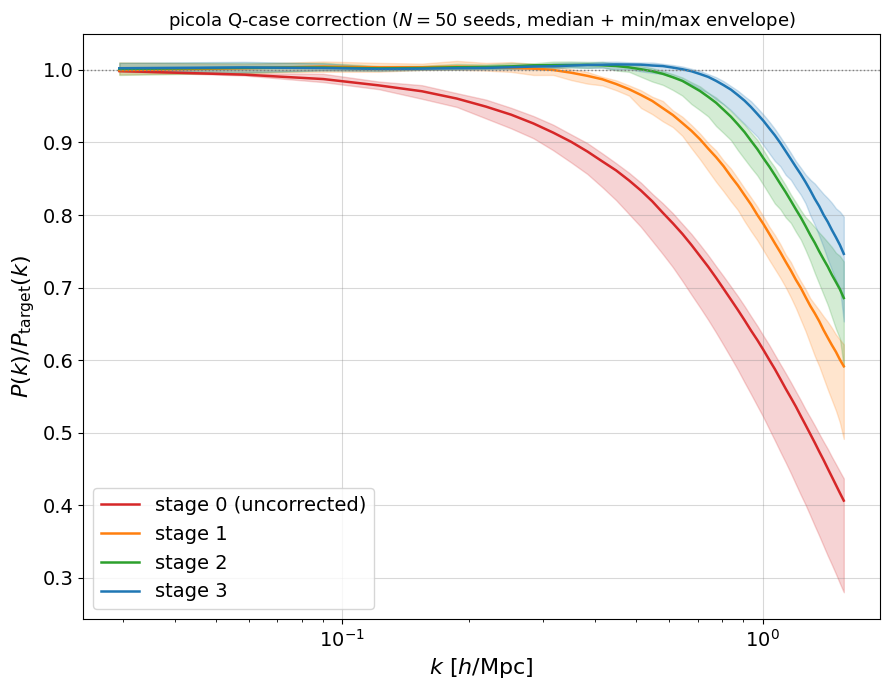

In [15]:
plot_pk_ratio_envelope_Q(QROOT, QUIJOTE_ROOT, "picola",figroot=os.path.join(basedir, "PICOLA"))

In [16]:
def get_boxsize(seed):
    #path = "/work/hdd/bdne/nchartier/quijote_lh/%d/snap_003" % seed
    #header = readgadget.header(path)
    #return header.boxsize / 1e3
    return 1000.


def load_saved_field(sim, seed, which, grid):
    '''which: "nb", "pm", or "it1"/"it2"/"it3"'''
    d = os.path.join(QROOT, sim, "seed%d" % seed)
    if which in ("nb", "pm"):
        fname = "delta_%s_grid%d.npy" % (which, grid)
    else:
        n = int(which.replace("it", ""))
        fname = "delta_corrected_it%d_grid%d.npy" % (n, grid)
    return np.load(os.path.join(d, fname))


def slice_2d(delta_3d, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max):
    '''z-averaged 2D (1+delta) slice out of a saved 3D delta grid.'''
    cell = BoxSize / grid
    ix_min, ix_max = int(round(x_min / cell)), int(round(x_max / cell))
    iy_min, iy_max = int(round(y_min / cell)), int(round(y_max / cell))
    iz_min, iz_max = int(round(z_min / cell)), int(round(z_max / cell))
    iz_max = max(iz_max, iz_min + 1)
    sub = delta_3d[ix_min:ix_max, iy_min:iy_max, iz_min:iz_max]
    return 1.0 + sub.mean(axis=2)


In [22]:
def plot_fields_slices(fields, labels, x_min, x_max, y_min, y_max, z_min, z_max,
                        scale='log', colmap='hot', dmin=0.1, dmax=100,
                        smooth_sigma=None, figroot=None, fname='dfield_slices.pdf',
                        log_transform=False):
    '''If log_transform=True, plot log10(2+delta) = log10(1+field) on a linear
    color scale instead of the raw (1+delta) field on a log color scale
    (the dmin/dmax clip still applies in the original 1+delta units, before
    the transform, so contrast control behaves the same either way).'''
    from scipy.ndimage import gaussian_filter

    n = len(fields)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 5.5),
                              sharey=True, constrained_layout=True)
    if n == 1:
        axes = [axes]

    fields = [np.clip(gaussian_filter(f, sigma=smooth_sigma) if smooth_sigma is not None else f,
                       dmin, dmax) for f in fields]

    if log_transform:
        fields = [np.log10(1.0 + f) for f in fields]  # log10(2+delta) = log10(1+(1+delta))
        norm = plt.Normalize(vmin=min(f.min() for f in fields), vmax=max(f.max() for f in fields))
    else:
        vmin = min(f.min() for f in fields)
        vmax = max(f.max() for f in fields)
        norm = LogNorm(vmin=vmin, vmax=vmax) if scale == 'log' else plt.Normalize(vmin=vmin, vmax=vmax)

    extent = [x_min, x_max, y_min, y_max]
    im = None
    for ax, field, label in zip(axes, fields, labels):
        im = ax.imshow(field.T, origin='lower', extent=extent,
                        cmap=colmap, norm=norm,
                        interpolation='sinc', aspect='equal')
        ax.set_title(label, fontsize=14)
        ax.set_xlabel(r'$x\ [h^{-1}\mathrm{Mpc}]$', fontsize=14)
    axes[0].set_ylabel(r'$y\ [h^{-1}\mathrm{Mpc}]$', fontsize=14)

    cbar = fig.colorbar(im, ax=axes, fraction=0.05, pad=0.02, aspect=30)
    cbar.set_label(r'$\log_{10}(2+\delta)$' if log_transform else r'$1+\delta$', fontsize=14)
    cbar.ax.tick_params(labelsize=12)
    fig.suptitle(r'$z \in [%.1f,\,%.1f]\ h^{-1}\mathrm{Mpc}$' % (z_min, z_max),
                  fontsize=16)

    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, fname), bbox_inches="tight")
    return fig, axes

def plot_density_slices(pos_list, labels, BoxSize, grid,
                         x_min, x_max, y_min, y_max, z_min, z_max,
                         scale='log', colmap='hot', dmin=0.1, dmax=100,
                         smooth_sigma=None, figroot=None,
                         fname='dfield_slices.pdf'):
    '''Original position-based version, now just a thin wrapper.'''
    fields = [compute_density_slice_2d(pos, BoxSize, grid,
                                        x_min, x_max, y_min, y_max, z_min, z_max)
              for pos in pos_list]
    return plot_fields_slices(fields, labels, x_min, x_max, y_min, y_max, z_min, z_max,
                               scale=scale, colmap=colmap, dmin=dmin, dmax=dmax,
                               smooth_sigma=smooth_sigma, figroot=figroot, fname=fname)


In [19]:
# import readgadget
# import bigfile

# def load_quijote(seed):
#     path = "/work/hdd/bdne/nchartier/quijote_lh/%d/snap_003" % seed
#     header = readgadget.header(path)
#     BoxSize = header.boxsize / 1e3
#     pos = readgadget.read_block(path, "POS ", [1]) / 1e3
#     return pos, BoxSize

# def load_fastpm(seed):
#     path = "/work/hdd/bdne/maho3/cmass-ili/quijotelike_for_nicolas/fastpm/L1000-N128/%d/fastpm_B2_0.6667" % seed
#     infile = bigfile.File(path)
#     return infile['1/Position'][:]

# def load_lpicola(seed):
#     path = "/work/hdd/bdne/nchartier/cola_lh/%d/Cola%d_512_20stepsnLPTpos0p5_z0p500" % (seed, seed)
#     return readgadget.read_block(path, "POS ", [1]) / 1e3


In [20]:

def load_quijote_delta(seed, grid):
    return np.load(os.path.join(QUIJOTE_ROOT, str(seed), "delta_grid%d.npy" % grid))


def load_saved_field(sim, seed, which, grid):
    if which == "nb":
        d = "/work/hdd/bdne/nchartier/quijote_lh/%d" % seed
        fname = "delta_grid%d.npy" % grid
    else:
        d = "/work/hdd/bdne/nchartier/Q_correction/%s/seed%d" % (sim, seed)
        if which == "pm":
            fname = "delta_pm_grid%d.npy" % grid
        else:
            fname = "delta_corrected_%s_grid%d.npy" % (which, grid)
    return np.load(os.path.join(d, fname))


def plot_stage_comparison(seed, stage, grid=512,
                           x_min=0., x_max=600., y_min=0., y_max=600.,
                           z_min=490., z_max=510.,
                           dmin=0.9, dmax=80, smooth_sigma=1.0,
                           figroot=figroot, log_transform=False):
    if stage not in (0, 1, 2, 3):
        raise ValueError("stage must be 0, 1, 2, or 3, got %r" % stage)

    which = "pm" if stage == 0 else "it%d" % stage
    stage_label = "initial" if stage == 0 else "%d Q correction%s" % (stage, "s" if stage > 1 else "")

    BoxSize = get_boxsize(seed)

    field_nb = load_quijote_delta(seed, grid)
    field_picola = load_saved_field("picola", seed, which, grid)
    field_fastpm = load_saved_field("fastpm", seed, which, grid)

    fields_2d = [slice_2d(f, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max)
                 for f in (field_nb, field_picola, field_fastpm)]

    fig, axes = plot_fields_slices(
        fields_2d,
        ["Quijote (target)", "L-PICOLA (%s)" % stage_label, "FastPM (%s)" % stage_label],
        x_min, x_max, y_min, y_max, z_min, z_max,
        scale='log', colmap='hot', dmin=dmin, dmax=dmax,
        smooth_sigma=smooth_sigma, figroot=None, log_transform=log_transform)

    fig.suptitle(r'seed %d, %s ($z \in [%.1f,\,%.1f]\ h^{-1}\mathrm{Mpc}$)' %
                 (seed, stage_label, z_min, z_max), fontsize=16)

    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fname = "dfield_slices_seed%d_stage%d.pdf" % (seed, stage)
        plt.savefig(os.path.join(figroot, fname), bbox_inches="tight")

    return fig, axes

    
def plot_density_phi_comparison(delta_nb, delta_pm, products_root, sim, slice_index=None, figroot=None, fname=None):
    d = os.path.join(products_root, sim)
    phi_corr = np.load(os.path.join(d, "phi_r_corr.npy"))
    phi_Q = np.load(os.path.join(d, "phi_r_Q.npy"))

    grid = delta_nb.shape[0]
    if slice_index is None:
        slice_index = grid // 2

    fields = [delta_nb[:, :, slice_index], delta_pm[:, :, slice_index],
              phi_corr[:, :, slice_index], phi_Q[:, :, slice_index]]
    titles = ["Target density", "PM density", r"$\phi$ (correlated case)", r"$\phi$ (uncorrelated case)"]

    fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
    axes = axes.ravel()
    for ax, field, title in zip(axes, fields, titles):
        im = ax.imshow(field, origin="lower", cmap="viridis")
        ax.set_title(title, fontsize=13)
        fig.colorbar(im, ax=ax, shrink=0.8)

    fig.suptitle(f"{sim}: density & potential slice comparison", fontsize=15)
    if figroot is not None and fname is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, fname), bbox_inches="tight")
    return fig, axes


In [23]:
PLOT_RESULTS_ROOT = "/u/nchartier/PkCorr/plot_results_products"

def plot_density_phi_comparison(sim, seed, grid, q_suffix,
                                 x_min=0., x_max=600., y_min=0., y_max=600.,
                                 z_min=490., z_max=510.,
                                 dmin=0.9, dmax=80, smooth_sigma=1.0,
                                 phi_vmax=None, figroot=None):
    BoxSize = get_boxsize(seed)

    field_nb = load_quijote_delta(seed, grid)
    field_pm = load_saved_field(sim, seed, "pm", grid)

    d = os.path.join(PLOT_RESULTS_ROOT, sim)
    phi_corr = np.load(os.path.join(d, "phi_r_corr.npy"))
    phi_Q = np.load(os.path.join(d, "phi_r_Q_%s.npy" % q_suffix))

    nb_2d = slice_2d(field_nb, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max)
    pm_2d = slice_2d(field_pm, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max)
    phi_corr_2d = slice_2d(phi_corr, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max)
    phi_Q_2d = slice_2d(phi_Q, BoxSize, grid, x_min, x_max, y_min, y_max, z_min, z_max)

    if phi_vmax is None:
        phi_vmax = max(np.abs(phi_corr_2d).max(), np.abs(phi_Q_2d).max())

    fig, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)

    for ax, field, title in zip(axes[:2], (nb_2d, pm_2d), ("Target density", "PM density")):
        im = ax.imshow(1 + field, origin="lower", cmap="hot",
                        norm=LogNorm(vmin=dmin, vmax=dmax))
        ax.set_title(title, fontsize=13)
        fig.colorbar(im, ax=ax, shrink=0.8)

    for ax, field, title in zip(axes[2:], (phi_corr_2d, phi_Q_2d),
                                 (r"$\phi$ (correlated case)", r"$\phi$ (uncorrelated case)")):
        im = ax.imshow(field, origin="lower", cmap="RdBu_r", vmin=-phi_vmax, vmax=phi_vmax)
        ax.set_title(title, fontsize=13)
        fig.colorbar(im, ax=ax, shrink=0.8)

    fig.suptitle(r'%s, seed %d ($z \in [%.1f,\,%.1f]\ h^{-1}\mathrm{Mpc}$)' %
                 (sim, seed, z_min, z_max), fontsize=16)

    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fname = "dfield_phi_slices_%s_seed%d.pdf" % (sim, seed)
        fig.savefig(os.path.join(figroot, fname), bbox_inches="tight")

    return fig, axes

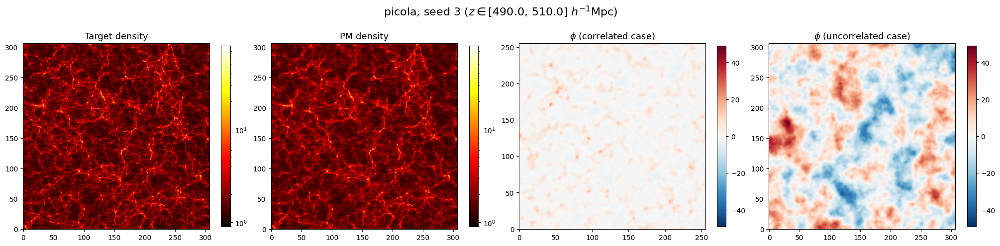

In [26]:
fig, axes = plot_density_phi_comparison("picola", 3, grid=512, q_suffix="picola_Q_50_bins_512_grid_seed3", figroot=figroot)

In [41]:
def load_bk_ratio_Q(qroot, quijote_root, sim, seed, which, k_min=None, k_max=None):
    d = os.path.join(qroot, sim, "seed%d" % seed)
    nb_dir = os.path.join(quijote_root, str(seed))

    ks = np.load(os.path.join(nb_dir, "ks_bispectrum.npy"))
    k_nb = np.load(os.path.join(nb_dir, "k.npy"))
    pk_nb = np.load(os.path.join(nb_dir, "pk.npy"))
    bk_nb = np.load(os.path.join(nb_dir, "bk.npy"))
    q_nb = compute_reduced_bispectrum(bk_nb, ks, k_nb, pk_nb)

    if which == "pm":
        bk_pm = np.load(os.path.join(d, "bk_pm_grid512.npy"))
        k_pm = np.load(os.path.join(d, "k_pm_grid512.npy"))
        pk_pm = np.load(os.path.join(d, "pk_pm_grid512.npy"))
    else:
        it = int(which)
        bk_pm = np.load(os.path.join(d, "bk_corrected_it%d.npy" % it))
        k_pm = np.load(os.path.join(d, "k_corrected_it%d.npy" % it))
        pk_pm = np.load(os.path.join(d, "pk_corrected_it%d.npy" % it))
    q_pm = compute_reduced_bispectrum(bk_pm, ks, k_pm, pk_pm)

    ratio = q_pm / q_nb
    mask = np.ones(len(ratio), dtype=bool)
    if k_min is not None:
        mask &= (ks[0] >= k_min) & (ks[1] >= k_min) & (ks[2] >= k_min)
    if k_max is not None:
        mask &= (ks[0] < k_max) & (ks[1] < k_max) & (ks[2] < k_max)
    return ratio[mask]



def plot_bk_ratio_grid_Q(qroot, quijote_root, sim, n_seeds=50, figroot=None, cmap_name="viridis",
                           color_by="seed", cosmo_params=None, k_max = None, k_min = None, sharey = False):
    '''color_by: "seed" or one of ["Omega_m","Omega_b","h","n_s","sigma_8"]
    (requires cosmo_params, e.g. from load_all_cosmo_params, when not "seed").'''
    if color_by != "seed" and cosmo_params is None:
        raise ValueError("cosmo_params must be provided when color_by is not 'seed'")

    stages = ["pm", "1", "2", "3"]
    titles = ["stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"]

    if color_by == "seed":
        color_vals = np.arange(n_seeds)
        cbar_label = "seed"
    else:
        color_vals = cosmo_params[color_by]
        cbar_label = color_by

    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=sharey, constrained_layout=True)
    axes = axes.ravel()
    cmap = plt.get_cmap(cmap_name)
    norm = plt.Normalize(vmin=np.nanmin(color_vals), vmax=np.nanmax(color_vals))

    for ax, stage, title in zip(axes, stages, titles):
        for seed in range(n_seeds):
            try:
                ratio = load_bk_ratio_Q(qroot, quijote_root, sim, seed, stage, k_max=k_max, k_min = k_min)
            except FileNotFoundError:
                continue
            ax.plot(np.arange(len(ratio)), ratio, color=cmap(norm(color_vals[seed])), alpha=0.8, lw=0.8)
        ax.axhline(1.0, color="white", lw=1, ls=":")
        ax.set_title(title, fontsize=12)
        ax.grid(color="grey", alpha=0.3)

    for ax in axes[2:]:
        ax.set_xlabel("triangle index", fontsize=15)
    for ax in axes[::2]:
        ax.set_ylabel(r"$Q_\mathrm{pm}/Q_\mathrm{target}$", fontsize=15)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes.tolist(), pad=0.02, aspect=40)
    cbar.set_label(cbar_label, fontsize=11)
    fig.suptitle(r"%s Q-case reduced bispectrum ratio (grid=512, $N=%d$ seeds)" % (sim, n_seeds),
                 fontsize=14)
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, f"bk_ratio_grid_Q_{sim}_by{color_by}.pdf"),
                     bbox_inches="tight")
    return fig, axes



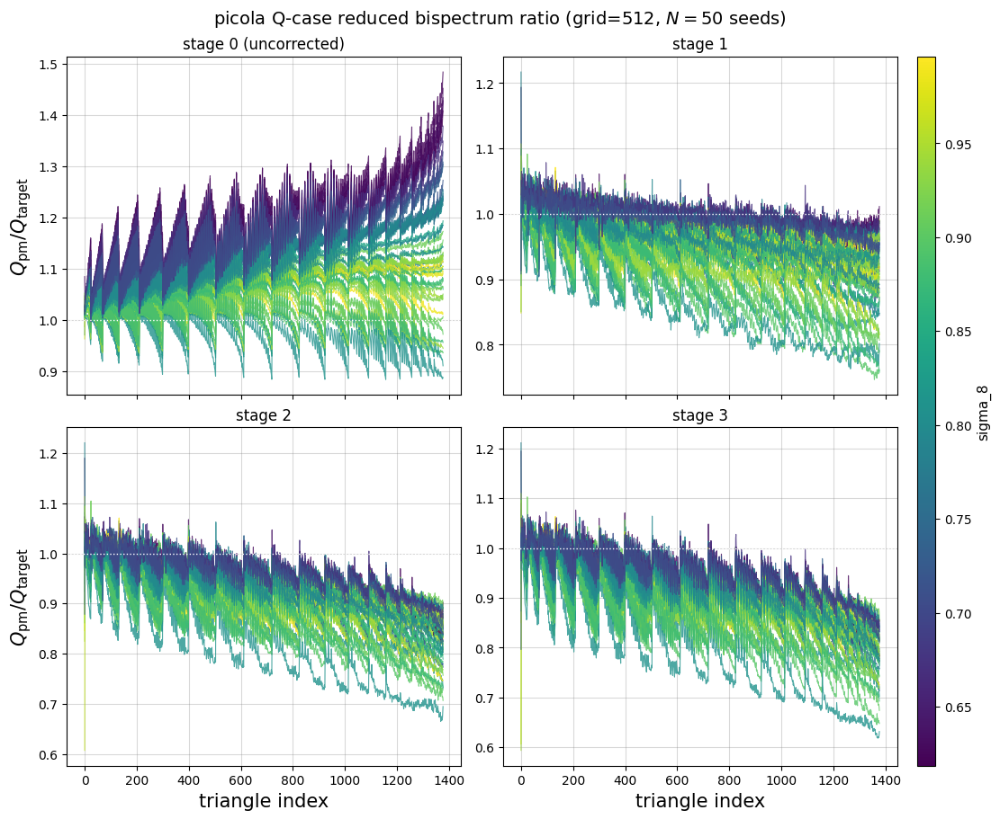

In [16]:
kmb  = None
fig, axes = plot_bk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "picola", figroot=os.path.join(basedir, "PICOLA"), 
                                 color_by="sigma_8", cosmo_params=cosmo_params, k_max = kmb)


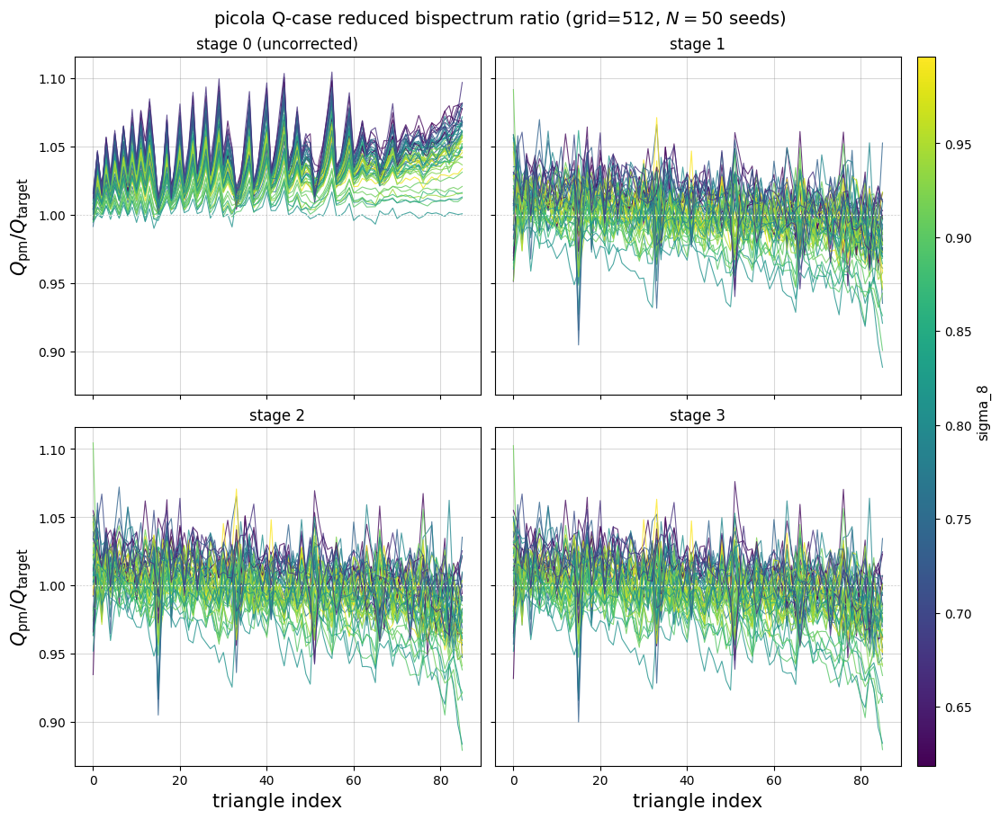

In [42]:
kmb  = 0.3; kmm = 0.025
fig, axes = plot_bk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "picola", figroot=os.path.join(basedir, "PICOLA"), 
                                 color_by="sigma_8", cosmo_params=cosmo_params, k_max = kmb, k_min = kmm, sharey = True)

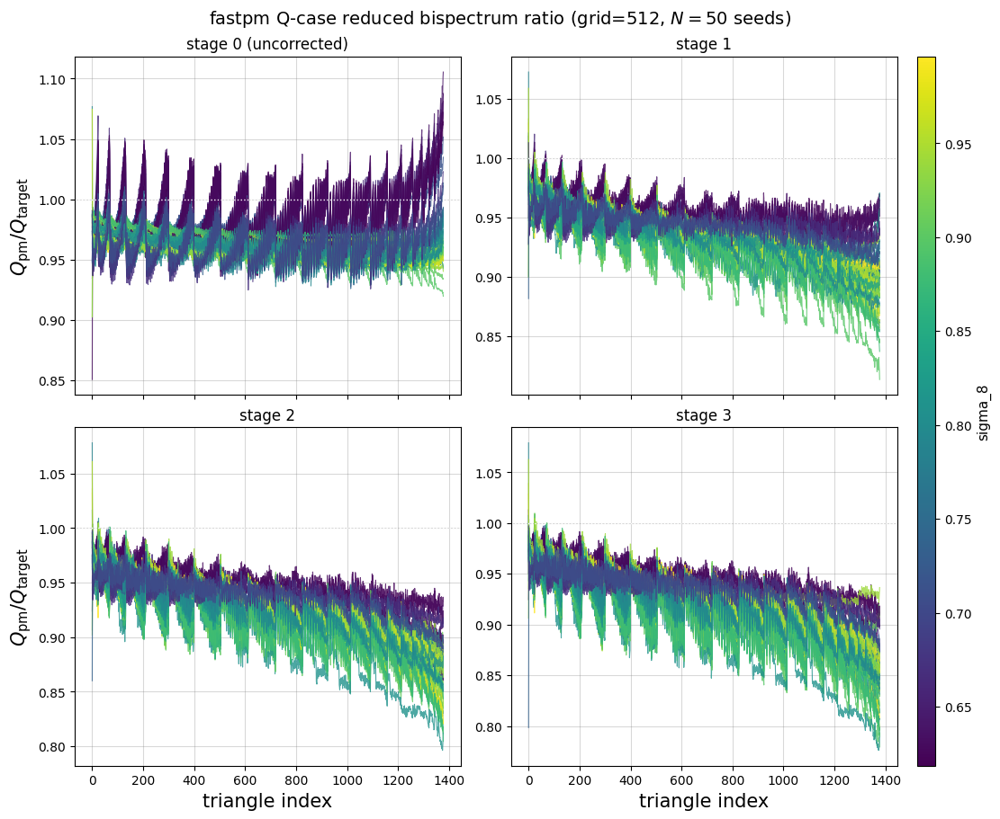

In [30]:
fig, axes = plot_bk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "fastpm", figroot=os.path.join(basedir, "FASTPM"), 
                                 color_by="sigma_8", cosmo_params=cosmo_params, k_max = None, k_min = None)

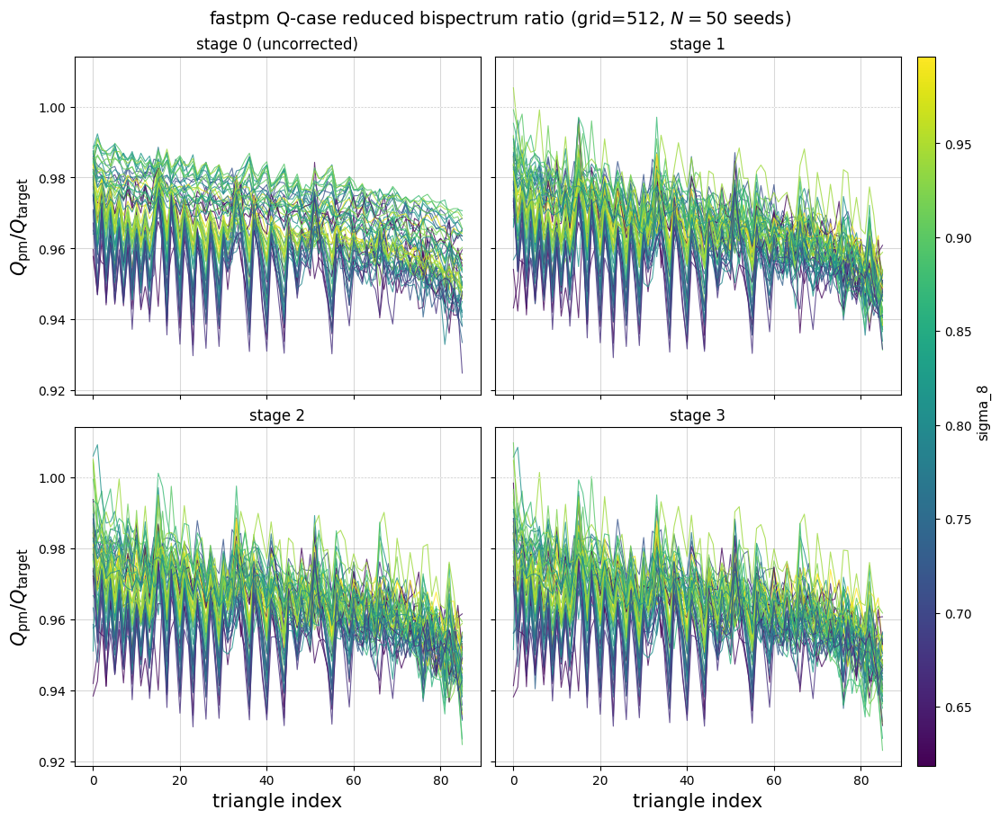

In [43]:
fig, axes = plot_bk_ratio_grid_Q(QROOT, QUIJOTE_ROOT, "fastpm", figroot=os.path.join(basedir, "FASTPM"), 
                                 color_by="sigma_8", cosmo_params=cosmo_params, k_max = kmb, k_min = kmm, sharey = True)


In [44]:
def plot_Qk_ratio_envelope_Q(qroot, quijote_root, sim, n_seeds=50, figroot=None,
                               k_min=None, k_max=None):
    stages = ["pm", "1", "2", "3"]
    labels = ["stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"]
    colors = ["tab:red", "tab:orange", "tab:green", "tab:blue"]

    fig, ax = plt.subplots(figsize=(9, 7))

    for stage, label, color in zip(stages, labels, colors):
        ratios = []
        n_tri = None
        for seed in range(n_seeds):
            try:
                ratio = load_bk_ratio_Q(qroot, quijote_root, sim, seed, stage,
                                         k_min=k_min, k_max=k_max)
            except FileNotFoundError:
                continue
            n_tri = len(ratio) if n_tri is None else min(n_tri, len(ratio))
            ratios.append(ratio)

        ratios = np.stack([r[:n_tri] for r in ratios])
        lo, hi = ratios.min(axis=0), ratios.max(axis=0)
        x = np.arange(n_tri)

        ax.plot(x, lo, color=color, lw=1.2, ls="--", label=label)
        ax.plot(x, hi, color=color, lw=1.2, ls="--")

    ax.axhline(1.0, color="grey", lw=1, ls=":")
    ax.set_xlabel("triangle index", fontsize=12)
    ax.set_ylabel(r"$Q_\mathrm{pm}/Q_\mathrm{target}$", fontsize=12)
    ax.set_title(f"{sim} Q-case reduced bispectrum ratio ($N={n_seeds}$ seeds, min/max envelope)",
                 fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(color="grey", alpha=0.3)
    plt.tight_layout()
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fname = f"Qk_ratio_envelope_Q_{sim}.pdf"
        plt.savefig(os.path.join(figroot, fname), bbox_inches="tight")
    return fig, ax

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'fastpm Q-case reduced bispectrum ratio ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

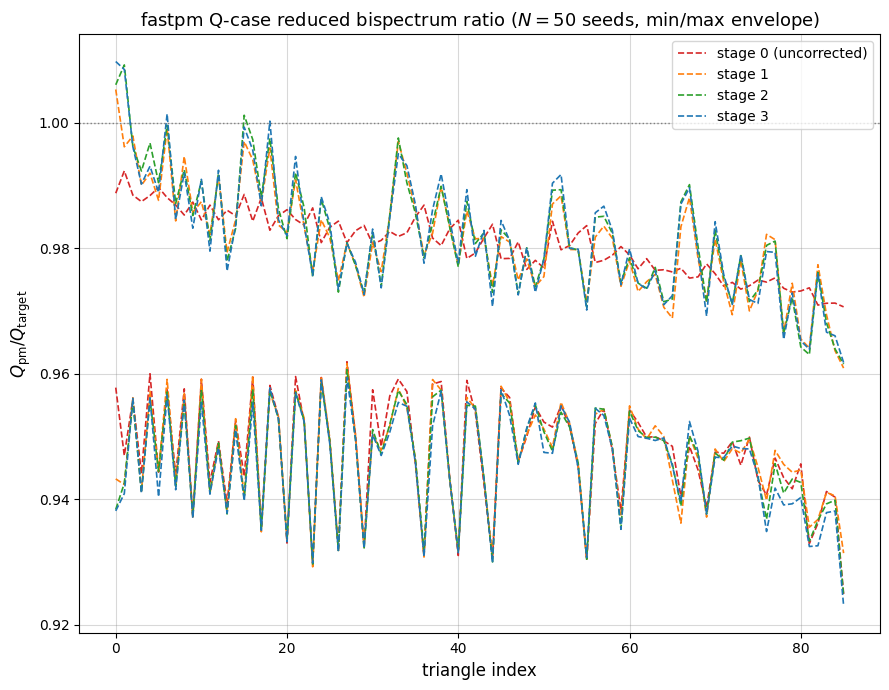

In [46]:
plot_Qk_ratio_envelope_Q(QROOT, QUIJOTE_ROOT, "fastpm", figroot=os.path.join(basedir, "FASTPM"), k_max = kmb, k_min = kmm)


(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'picola Q-case reduced bispectrum ratio ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

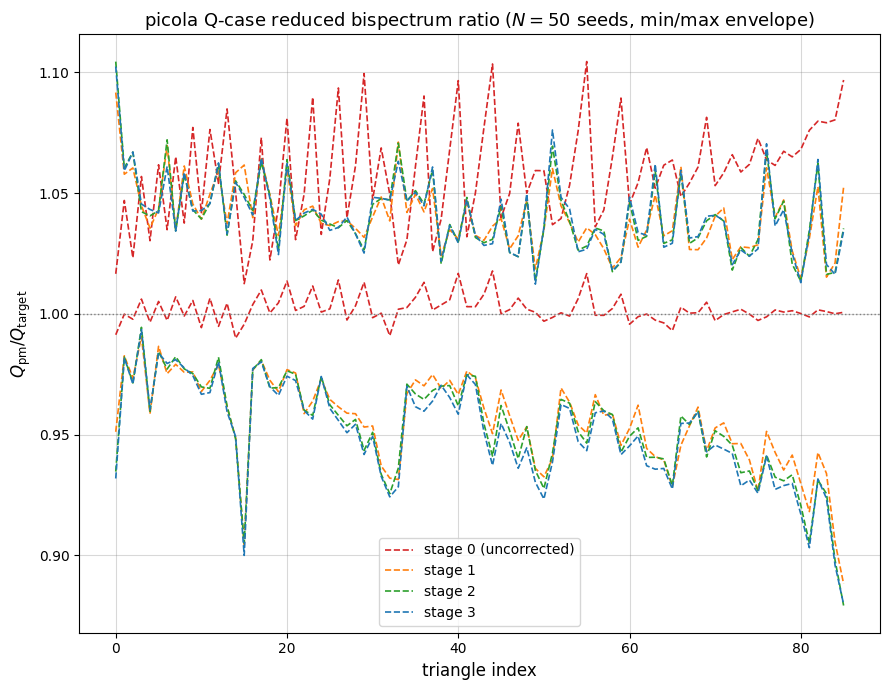

In [47]:
plot_Qk_ratio_envelope_Q(QROOT, QUIJOTE_ROOT, "picola", figroot=os.path.join(basedir, "PICOLA"), k_max = kmb, k_min = kmm)

# After Corr correction with lr

In [52]:
def resolve_early_stopped_stage(corr_root, quijote_root, sim, seed, grid, requested_stage, n_iterations=3):
    '''Walks pm -> 1 -> 2 -> ... up to requested_stage, freezing at the last stage
    that did not get worse (by max|ratio-1|) than the one before it. E.g. if
    stage 3's divergence > stage 2's, requesting "3" returns "2" instead.'''
    stages = ["pm"] + [str(it) for it in range(1, n_iterations + 1)]
    target_idx = stages.index(requested_stage)

    try:
        _, ratio0 = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, stages[0], grid)
    except FileNotFoundError:
        return None
    best_stage, best_div = stages[0], np.nanmax(np.abs(ratio0 - 1.0))

    for stage in stages[1:target_idx + 1]:
        try:
            _, ratio = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, stage, grid)
        except FileNotFoundError:
            break
        div = np.nanmax(np.abs(ratio - 1.0))
        if div > best_div:
            break
        best_stage, best_div = stage, div

    return best_stage

In [59]:
def load_pk_ratio_corr(corr_root, quijote_root, sim, seed, which, grid, early_stop=False, n_iterations=3):
    if early_stop:
        which = resolve_early_stopped_stage(corr_root, quijote_root, sim, seed, grid, which,
                                              n_iterations=n_iterations)
        if which is None:
            raise FileNotFoundError(f"no data at all for seed {seed}")

    d = os.path.join(corr_root, sim, "seed%d" % seed)
    if which == "pm":
        k = np.load(os.path.join(d, f"k_pm_grid{grid}.npy"))
        pk = np.load(os.path.join(d, f"pk_pm_grid{grid}.npy"))
    else:
        it = int(which)
        k = np.load(os.path.join(d, f"k_corrected_it{it}_grid{grid}.npy"))
        pk = np.load(os.path.join(d, f"pk_corrected_it{it}_grid{grid}.npy"))

    nb_dir = os.path.join(quijote_root, str(seed))
    if grid == 512:
        k_nb_ = np.load(os.path.join(nb_dir, "k.npy"))
        pk_nb_ = np.load(os.path.join(nb_dir, "pk.npy"))
    else:
        k_nb_ = np.load(os.path.join(nb_dir, f"k_grid{grid}.npy"))
        pk_nb_ = np.load(os.path.join(nb_dir, f"pk_grid{grid}.npy"))

    valid = k >= k_nb_.min()
    k, pk = k[valid], pk[valid]
    pk_nb_i = np.interp(k, k_nb_, pk_nb_)
    return k, pk / pk_nb_i

def plot_pk_ratio_grid_corr(corr_root, quijote_root, sim, lr, grid, n_seeds=50, figroot=None,
                              cmap_name="viridis", color_by="seed", cosmo_params=None,
                              stages=("pm", "1", "2", "3"),
                              titles=("stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"),
                              early_stop=False):
    if color_by != "seed" and cosmo_params is None:
        raise ValueError("cosmo_params must be provided when color_by is not 'seed'")
    if len(stages) != len(titles):
        raise ValueError("stages and titles must be the same length")

    color_vals = np.arange(n_seeds) if color_by == "seed" else cosmo_params[color_by]
    cbar_label = "seed" if color_by == "seed" else color_by

    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True, constrained_layout=True)
    axes = axes.ravel()

    cmap = plt.get_cmap(cmap_name)
    norm = plt.Normalize(vmin=np.nanmin(color_vals), vmax=np.nanmax(color_vals))

    for ax, stage, title in zip(axes, stages, titles):
        for seed in range(n_seeds):
            try:
                k, ratio = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, stage, grid,
                                               early_stop=early_stop)
            except FileNotFoundError:
                continue
            ax.plot(k, ratio, color=cmap(norm(color_vals[seed])), alpha=0.8, lw=0.8)
        ax.axhline(1.0, color="white", lw=1, ls=":")
        ax.set_xscale("log")
        ax.set_title(title, fontsize=12)
        ax.grid(color="grey", alpha=0.3)

    for ax in axes[2:]:
        ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$", fontsize=12)
    for ax in axes[::2]:
        ax.set_ylabel(r"$P(k)/P_\mathrm{target}(k)$", fontsize=12)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes.tolist(), pad=0.02, aspect=40)
    cbar.set_label(cbar_label, fontsize=11)
    fig.suptitle(r"%s corr-case correction, grid=%d, $\mathrm{lr}=%.2f$  ($N=%d$ seeds)"
                 % (sim, grid, lr, n_seeds), fontsize=14)
    tag = "_earlystop" if early_stop else ""
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, f"pk_ratio_grid_{sim}_grid{grid}_by{color_by}{tag}.pdf"),
                     bbox_inches="tight")
    return fig, axes

def plot_pk_ratio_envelope_corr(corr_root, quijote_root, sim, lr, grid, n_seeds=50, figroot=None,
                                  stages=("pm", "1", "2", "3"),
                                  labels=("stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"),
                                  colors=("tab:red", "tab:orange", "tab:green", "tab:blue"),
                                  early_stop=False):
    
    fig, ax = plt.subplots(figsize=(9, 7))
    k_ref = None

    for stage, label, color in zip(stages, labels, colors):
        ratios = []
        for seed in range(n_seeds):
            try:
                k, ratio = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, stage, grid,
                                               early_stop=early_stop)
            except FileNotFoundError:
                continue
            if k_ref is None:
                k_ref = k
            ratios.append(np.interp(k_ref, k, ratio))
        ratios = np.stack(ratios)
        median = np.median(ratios, axis=0)
        lo, hi = ratios.min(axis=0), ratios.max(axis=0)
        ax.plot(k_ref, median, color=color, lw=1.8, label=label)
        ax.fill_between(k_ref, lo, hi, color=color, alpha=0.2)

    ax.axhline(1.0, color="grey", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$", fontsize=12)
    ax.set_ylabel(r"$P(k)/P_\mathrm{target}(k)$", fontsize=12)
    ax.set_title(r"%s corr-case, grid=%d, $\mathrm{lr}=%.2f$ ($N=%d$ seeds, median + min/max envelope)"
                 % (sim, grid, lr, n_seeds), fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(color="grey", alpha=0.3)
    plt.tight_layout()
    stages_tag = "_".join(stages)
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, f"pk_ratio_envelope_{sim}_grid{grid}_{stages_tag}.pdf"),
                     bbox_inches="tight")
    return fig, ax

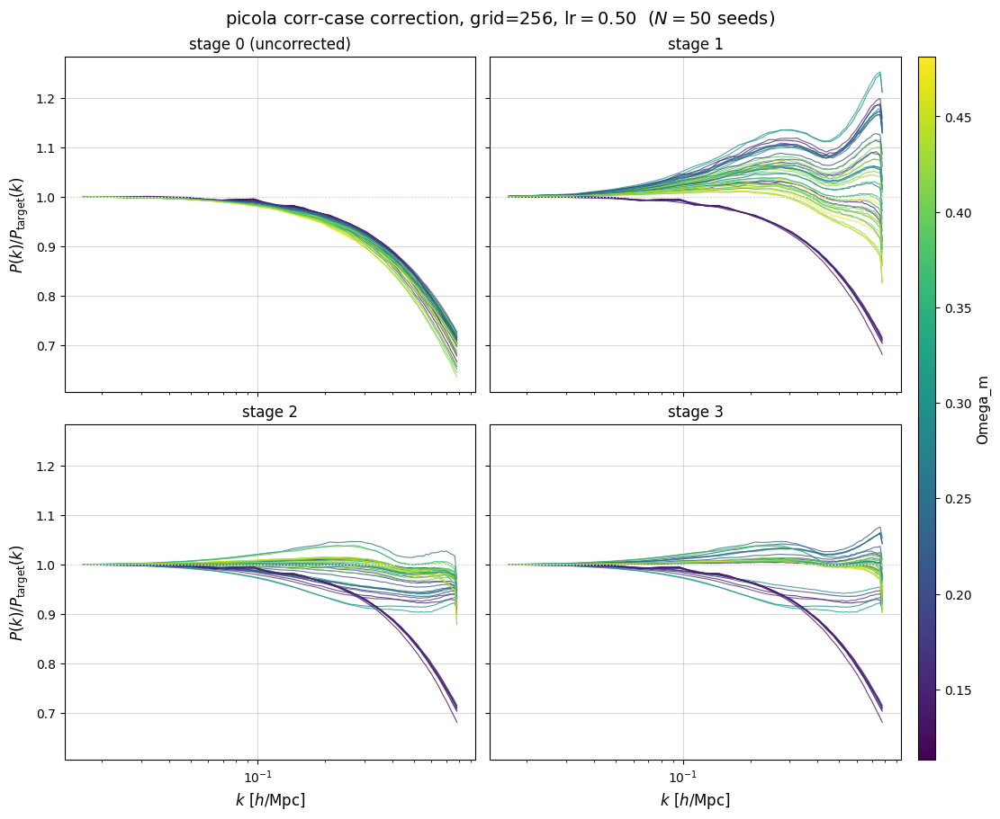

In [60]:
basedir = "."

cosmo_params = load_all_cosmo_params(QUIJOTE_ROOT, n_seeds=50)
#fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "picola", lr=0.5, grid=256, figroot=os.path.join(basedir, "PICOLA"), color_by ="Omega_m", cosmo_params = cosmo_params)
fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "picola", lr=0.5, grid=256, figroot=os.path.join(basedir, "PICOLA"), color_by ="Omega_m", cosmo_params = cosmo_params, early_stop=True)


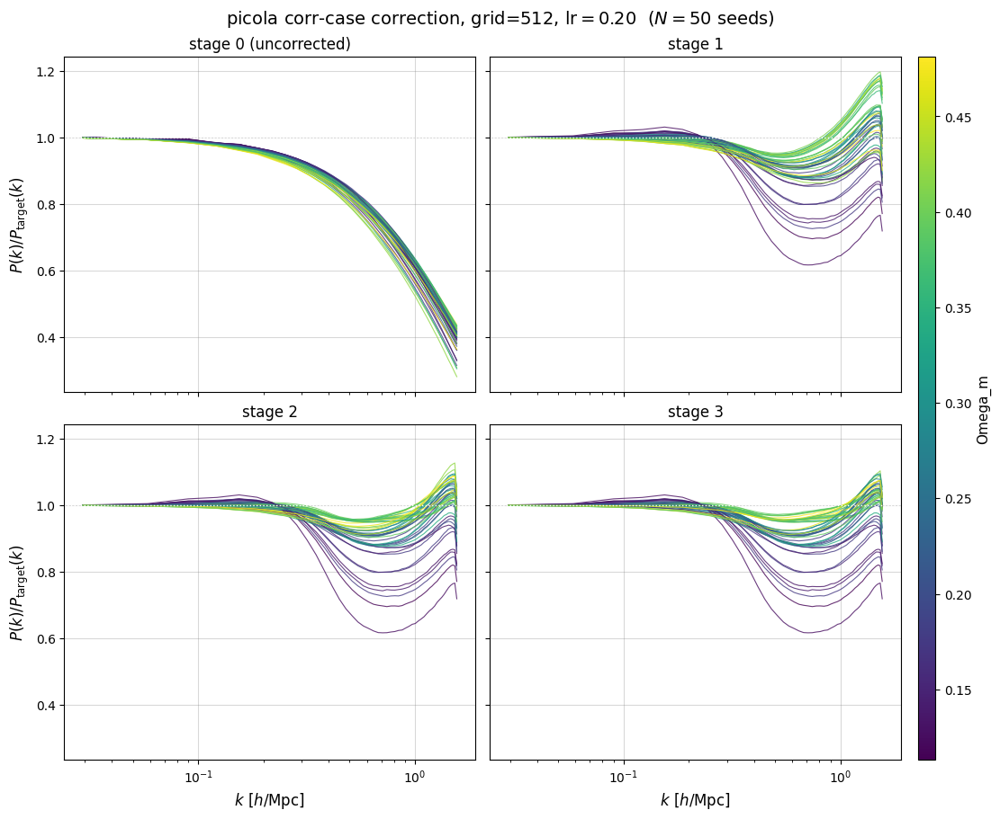

In [61]:
fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "picola", lr=0.2, grid=512, figroot=os.path.join(basedir, "PICOLA"), color_by ="Omega_m", cosmo_params = cosmo_params, early_stop=True)


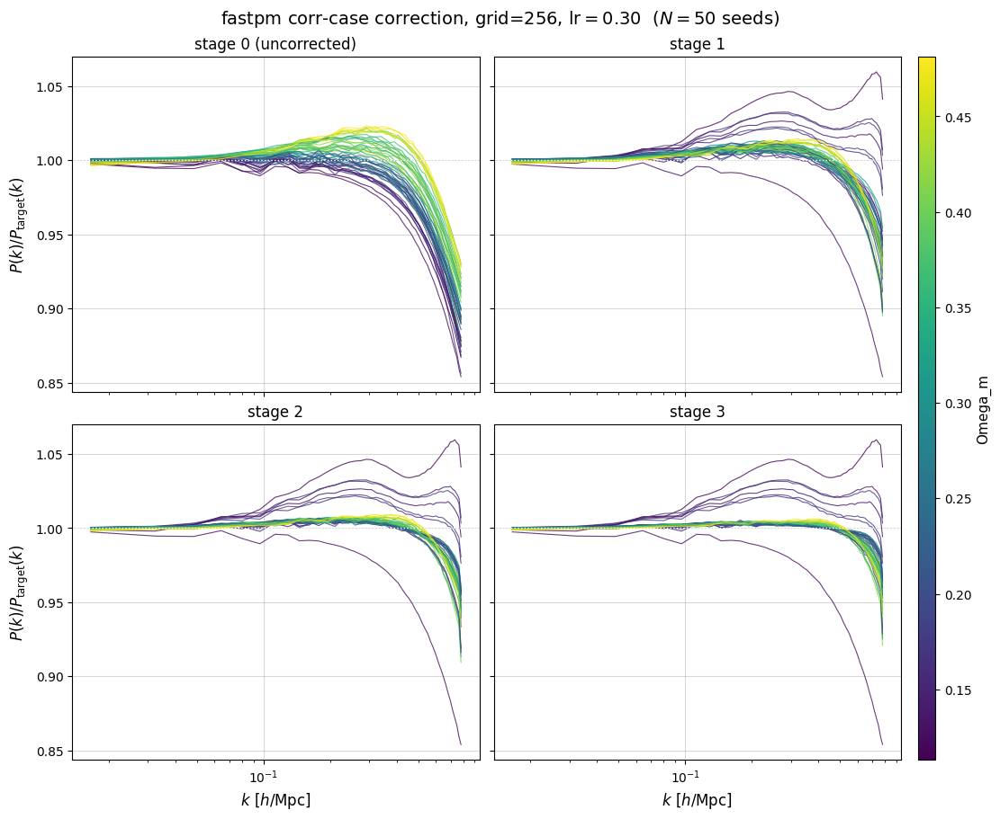

In [62]:
#fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, "fastpm", lr=0.3, grid=256, figroot=os.path.join(basedir, "FASTPM"))
#fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "fastpm", lr=0.3, grid=256, figroot=os.path.join(basedir, "FASTPM"), color_by ="Omega_m", cosmo_params = cosmo_params)
fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "fastpm", lr=0.3, grid=256, figroot=os.path.join(basedir, "FASTPM"), color_by ="Omega_m", cosmo_params = cosmo_params, early_stop=True)

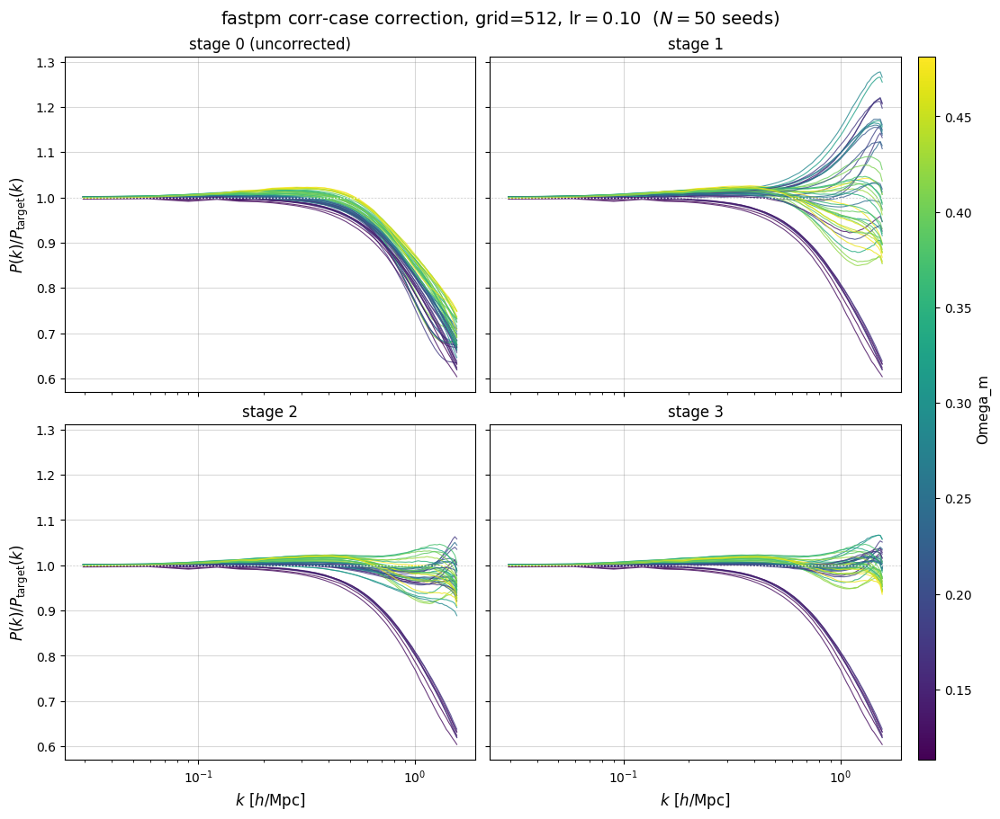

In [63]:
#fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT,QUIJOTE_ROOT, "fastpm", lr=0.1, grid=512, figroot=os.path.join(basedir, "FASTPM"), color_by ="Omega_m", cosmo_params = cosmo_params)
fig, axes = plot_pk_ratio_grid_corr(CORR_ROOT, QUIJOTE_ROOT, "fastpm", lr=0.1, grid=512, figroot=os.path.join(basedir, "FASTPM"), color_by ="Omega_m", cosmo_params = cosmo_params, early_stop=True)

In [64]:
_trapz = getattr(np, "trapz", None) or np.trapezoid

def build_bispectrum_matrix(k, ks, bk):
    n_k = len(k)
    def k_to_idx(k_val):
        return int(np.argmin(np.abs(k - k_val)))
    I_inner = np.zeros((n_k, n_k))
    for k1 in np.unique(ks[0, :]):
        i = k_to_idx(k1)
        sel = np.where(ks[0, :] == k1)[0]
        k2_all = ks[1, sel]; k3_all = ks[2, sel]; bk_all = bk[sel]
        for k2 in np.unique(k2_all):
            j = k_to_idx(k2)
            mask = (k2_all == k2)
            k3_sub = k3_all[mask]; bk_sub = bk_all[mask]
            y_sub = (k1**2 + k2**2 - k3_sub**2) / (2*k1*k2)
            order = np.argsort(y_sub)
            I_inner[i, j] = _trapz(y_sub[order]*bk_sub[order], y_sub[order])
    I_inner += np.tril(I_inner, -1).T
    dk = np.empty(n_k)
    dk[1:-1] = (k[2:] - k[:-2]) / 2
    dk[0] = (k[1] - k[0]) / 2
    dk[-1] = (k[-1] - k[-2]) / 2
    M = (1/(2*np.pi**2)) * k[:, None] * k[None, :] * I_inner * dk[None, :]
    return M

In [65]:
def compute_seed_divergence_pair(corr_root, quijote_root, sim, grid, stage, n_seeds=50):
    div_pm = np.full(n_seeds, np.nan)
    div_stage = np.full(n_seeds, np.nan)
    for seed in range(n_seeds):
        try:
            _, ratio_pm = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, "pm", grid)
            div_pm[seed] = np.nanmax(np.abs(ratio_pm - 1.0))
        except FileNotFoundError:
            pass
        try:
            _, ratio_stage = load_pk_ratio_corr(corr_root, quijote_root, sim, seed, stage, grid)
            div_stage[seed] = np.nanmax(np.abs(ratio_stage - 1.0))
        except FileNotFoundError:
            pass
    return div_pm, div_stage


def plot_divergence_scatter(corr_root, quijote_root, sim, grid, stage, n_seeds=50, figroot=None):
    div_pm, div_stage = compute_seed_divergence_pair(corr_root, quijote_root, sim, grid, stage, n_seeds)

    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(div_pm, div_stage, c=range(n_seeds), cmap="spring", s=40)
    lims = [0, np.nanmax([np.nanmax(div_pm), np.nanmax(div_stage)]) * 1.05]
    ax.plot(lims, lims, color="grey", ls=":", lw=1, label="no change (y=x)")
    ax.set_xlabel("max |P_pm/P_target - 1|  (before)")
    ax.set_ylabel(f"max |P_it{stage}/P_target - 1|  (after, stage {stage})")
    ax.set_title(f"{sim}, grid={grid}: divergence before vs. after correction")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    plt.colorbar(sc, ax=ax, label="seed")
    plt.tight_layout()
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, f"divergence_scatter_{sim}_grid{grid}_stage{stage}.pdf"),
                     bbox_inches="tight")
    return fig, ax

def plot_divergence_vs_cosmo(cosmo_params, divergence, param_x, param_y, sim, grid, stage,
                               figroot=None):
    fig, ax = plt.subplots(figsize=(7, 6))
    sc = ax.scatter(cosmo_params[param_x], cosmo_params[param_y], c=divergence,
                     cmap="spring", s=60, edgecolor="k", linewidth=0.3)
    ax.set_xlabel(param_x, fontsize=12)
    ax.set_ylabel(param_y, fontsize=12)
    ax.set_title(f"{sim}, grid={grid}, stage {stage}: divergence vs. cosmology", fontsize=13)
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(f"max |P_it{stage}/P_target - 1|", fontsize=11)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot,
                     f"divergence_vs_cosmo_{sim}_grid{grid}_stage{stage}_{param_x}_{param_y}.pdf"),
                     bbox_inches="tight")
    return fig, ax
def load_gamma_before_state(corr_root, qroot, sim, seed, grid, stage):
    '''stage is the iteration the gamma solve feeds INTO: "1" -> gamma computed from
    the pm baseline; "3" -> gamma computed from iteration 2's output.'''
    it = int(stage)
    if it == 1:
        d = os.path.join(qroot, sim, "seed%d" % seed)
        k_before = np.load(os.path.join(d, f"k_pm_grid{grid}.npy"))
        Pk_before = np.load(os.path.join(d, f"pk_pm_grid{grid}.npy"))
    else:
        d = os.path.join(corr_root, sim, "seed%d" % seed)
        k_before = np.load(os.path.join(d, f"k_corrected_it{it-1}_grid{grid}.npy"))
        Pk_before = np.load(os.path.join(d, f"pk_corrected_it{it-1}_grid{grid}.npy"))
    return k_before, Pk_before


def compute_gamma_for_seed(qroot, quijote_root, corr_root, sim, seed, grid, stage):
    
    pm_dir = os.path.join(qroot, sim, "seed%d" % seed)
    nb_dir = os.path.join(quijote_root, str(seed))

    if grid == 512:
        k_nb = np.load(os.path.join(nb_dir, "k.npy"))
        Pk_nb = np.load(os.path.join(nb_dir, "pk.npy"))
        ks = np.load(os.path.join(nb_dir, "ks_bispectrum.npy"))
    else:
        k_nb = np.load(os.path.join(nb_dir, f"k_grid{grid}.npy"))
        Pk_nb = np.load(os.path.join(nb_dir, f"pk_grid{grid}.npy"))
        ks = np.load(os.path.join(pm_dir, f"ks_bispectrum_grid{grid}.npy"))

    k_pm = np.load(os.path.join(pm_dir, f"k_pm_grid{grid}.npy"))
    bk_pm = np.load(os.path.join(pm_dir, f"bk_pm_grid{grid}.npy"))
    M = build_bispectrum_matrix(k_pm, ks, bk_pm)

    k_before, Pk_before = load_gamma_before_state(corr_root, qroot, sim, seed, grid, stage)
    Pk_ref_i = np.interp(k_before, k_nb, Pk_nb)

    A = 2 * np.diag(Pk_before) + M
    gamma_sol = np.linalg.solve(A, Pk_ref_i - Pk_before)
    return k_before, gamma_sol


def plot_gamma_lines_vs_cosmo(qroot, quijote_root, corr_root, sim, grid, stage, cosmo_params,
                                param, n_seeds=50, figroot=None):
    vals = cosmo_params[param]
    norm = plt.Normalize(vmin=vals.min(), vmax=vals.max())
    cmap = plt.get_cmap("spring")

    fig, ax = plt.subplots(figsize=(8, 6))
    for seed in range(n_seeds):
        try:
            k, gamma = compute_gamma_for_seed(qroot, quijote_root, corr_root, sim, seed, grid, stage)
        except FileNotFoundError:
            continue
        ax.plot(k, gamma, color=cmap(norm(vals[seed])), alpha=0.8, lw=1.0)

    ax.axhline(0.0, color="grey", lw=1, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$", fontsize=16)
    ax.set_ylabel(r"$\gamma_k$", fontsize=16)
    ax.set_title(f"{sim}, grid={grid}: gamma_k into stage {stage}", fontsize=13)
    ax.grid(alpha=0.3)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label(param, fontsize=15)

    plt.tight_layout()
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, f"gamma_vs_{param}_{sim}_grid{grid}_stage{stage}.pdf"),
                     bbox_inches="tight")
    return fig, ax


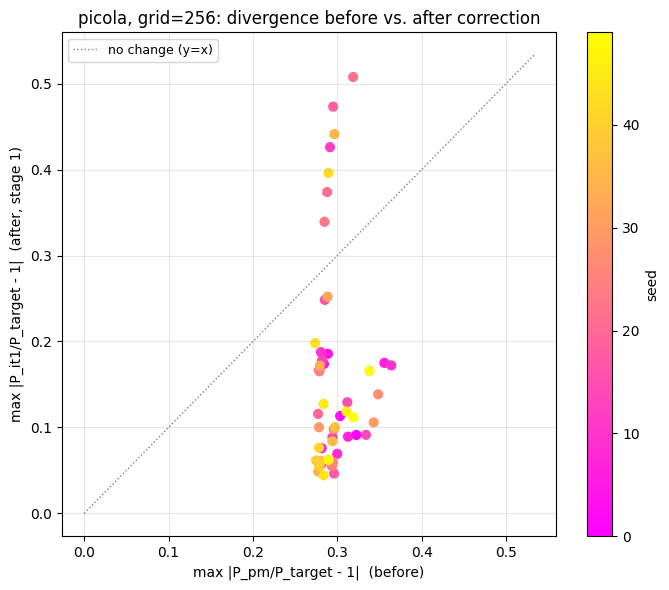

In [66]:
sim, grid, stage = "picola", 256, "1"
cosmo_params = load_all_cosmo_params(QUIJOTE_ROOT, n_seeds=50)

fig, ax = plot_divergence_scatter(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)


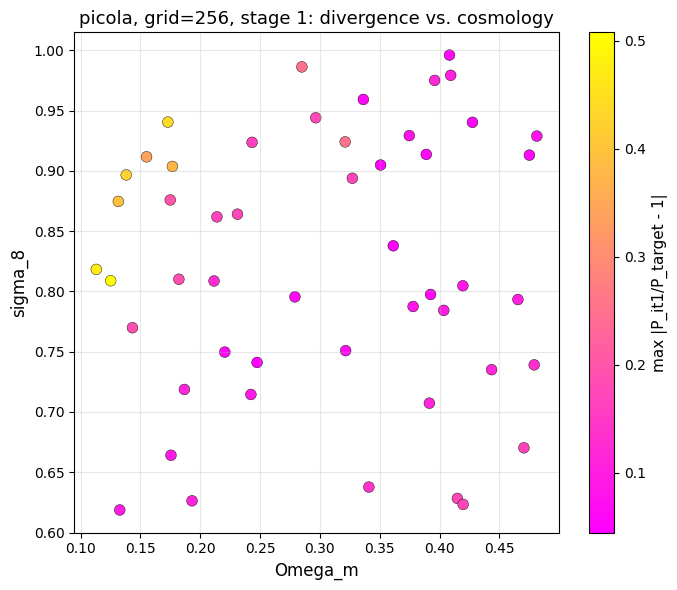

In [67]:
_, div_stage = compute_seed_divergence_pair(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)
fig, ax = plot_divergence_vs_cosmo(cosmo_params, div_stage, "Omega_m", "sigma_8", sim, grid, stage)


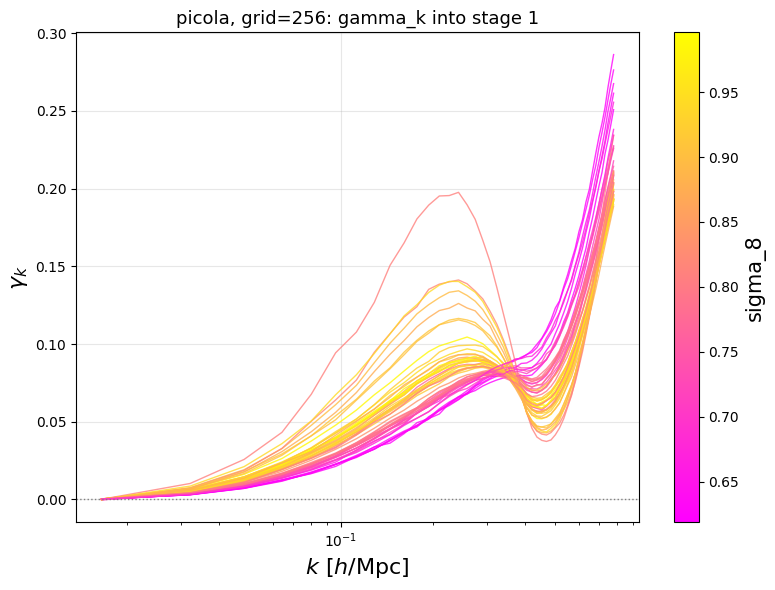

In [68]:
fig, ax = plot_gamma_lines_vs_cosmo(QROOT, QUIJOTE_ROOT, CORR_ROOT, sim, grid, stage, cosmo_params, "sigma_8")


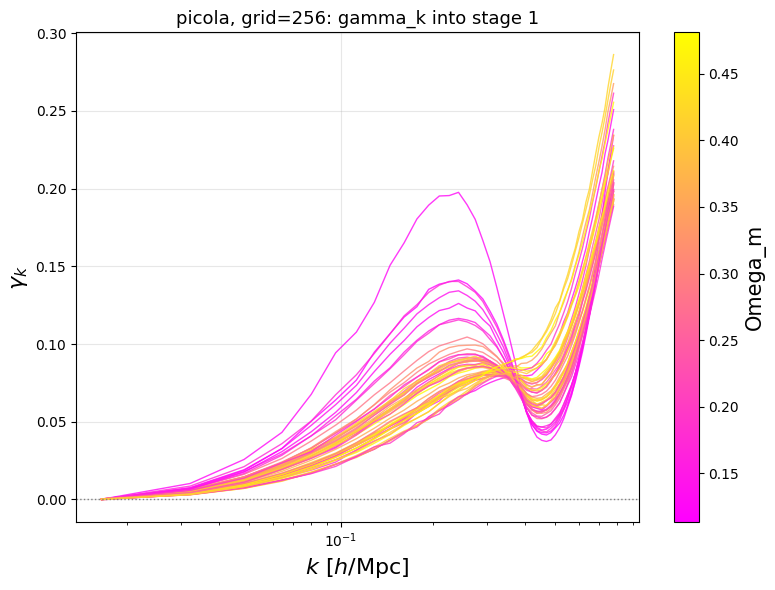

In [69]:
fig, ax = plot_gamma_lines_vs_cosmo(QROOT, QUIJOTE_ROOT, CORR_ROOT, sim, grid, stage, cosmo_params, "Omega_m")

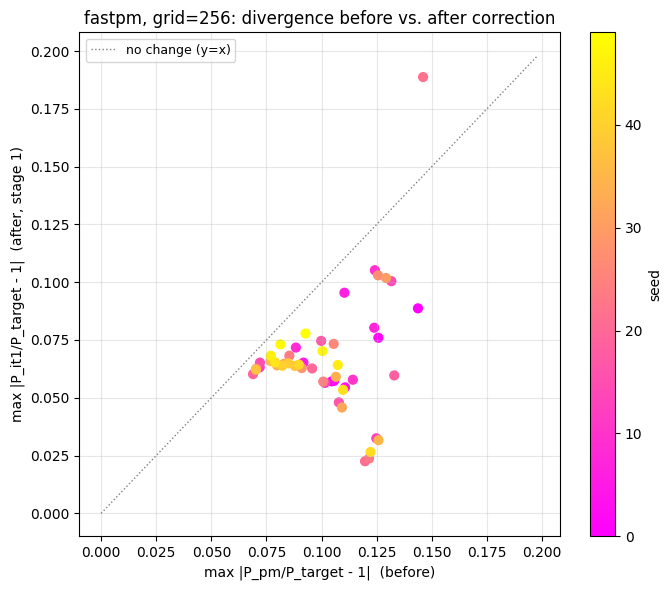

In [70]:
sim, grid, stage = "fastpm", 256, "1"
cosmo_params = load_all_cosmo_params(QUIJOTE_ROOT, n_seeds=50)

fig, ax = plot_divergence_scatter(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)

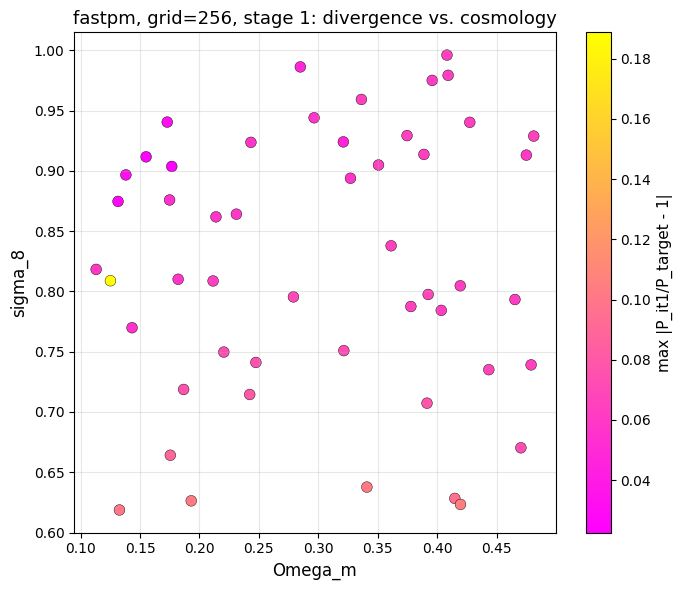

In [71]:
_, div_stage = compute_seed_divergence_pair(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)
fig, ax = plot_divergence_vs_cosmo(cosmo_params, div_stage, "Omega_m", "sigma_8", sim, grid, stage)

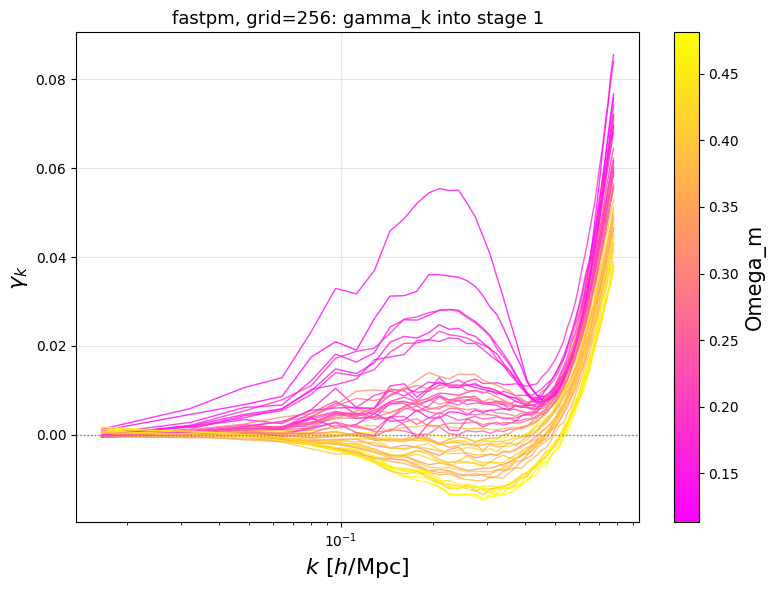

In [72]:
fig, ax = plot_gamma_lines_vs_cosmo(QROOT, QUIJOTE_ROOT, CORR_ROOT, sim, grid, stage, cosmo_params, "Omega_m")

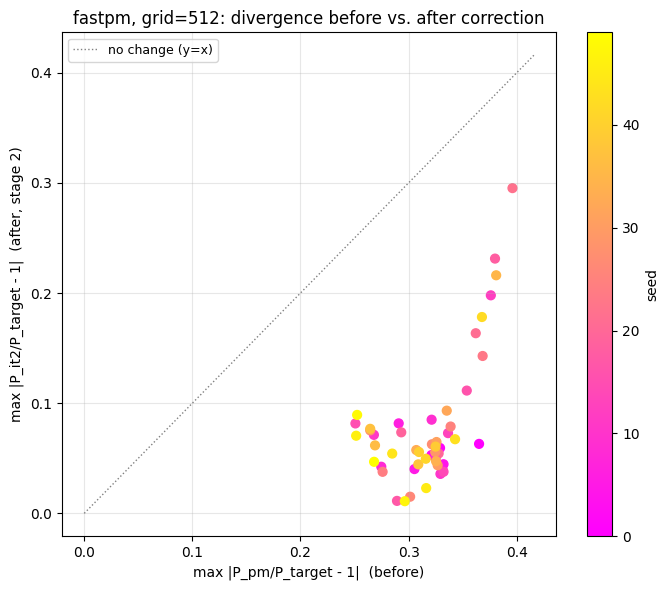

In [73]:
sim, grid, stage = "fastpm", 512, "2"
cosmo_params = load_all_cosmo_params(QUIJOTE_ROOT, n_seeds=50)

fig, ax = plot_divergence_scatter(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)

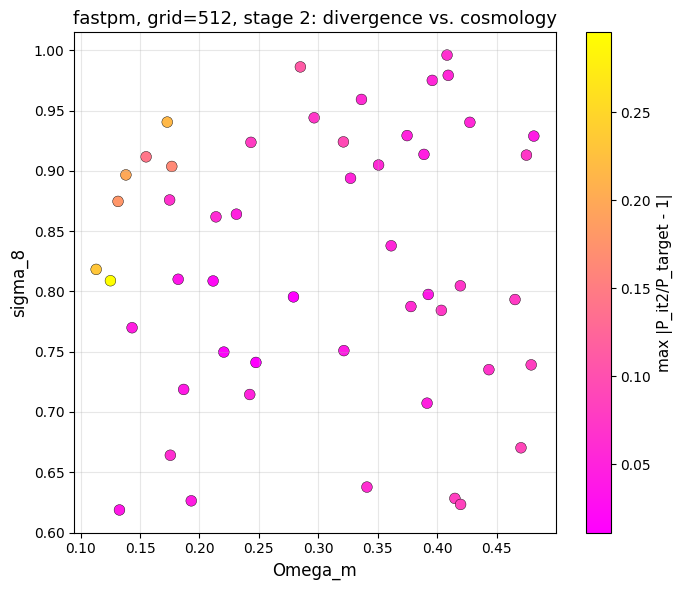

In [74]:
_, div_stage = compute_seed_divergence_pair(CORR_ROOT, QUIJOTE_ROOT, sim, grid, stage)
fig, ax = plot_divergence_vs_cosmo(cosmo_params, div_stage, "Omega_m", "sigma_8", sim, grid, stage)

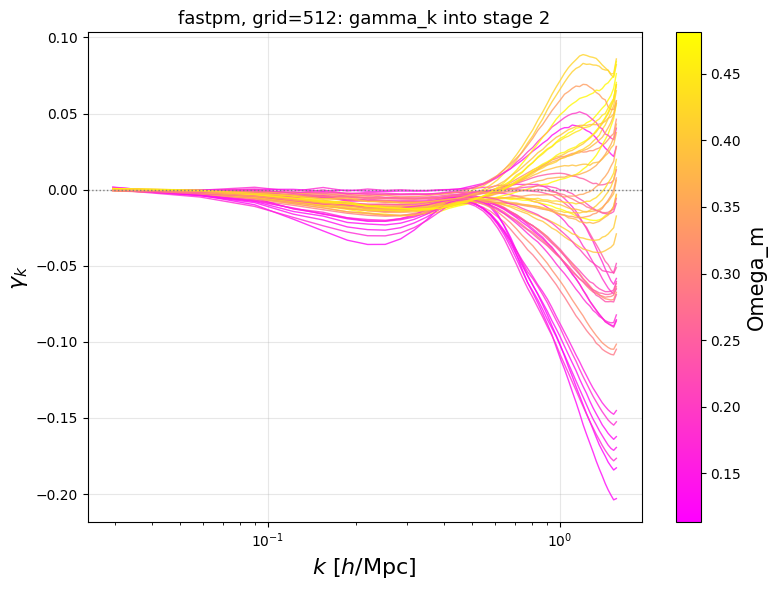

In [75]:
fig, ax = plot_gamma_lines_vs_cosmo(QROOT, QUIJOTE_ROOT, CORR_ROOT, sim, grid, stage, cosmo_params, "Omega_m")

In [77]:
def load_bk_ratio_corr(corr_root, qroot, quijote_root, sim, seed, which, grid, k_min=None,
                         k_max=None, early_stop=False, n_iterations=3):
    if early_stop:
        which = resolve_early_stopped_stage(corr_root, quijote_root, sim, seed, grid, which,
                                              n_iterations=n_iterations)
        if which is None:
            raise FileNotFoundError(f"no data at all for seed {seed}")
    # ... rest unchanged

    pm_dir = os.path.join(qroot, sim, "seed%d" % seed)
    nb_dir = os.path.join(quijote_root, str(seed))

    if grid == 512:
        ks = np.load(os.path.join(nb_dir, "ks_bispectrum.npy"))
        k_nb = np.load(os.path.join(nb_dir, "k.npy"))
        pk_nb = np.load(os.path.join(nb_dir, "pk.npy"))
        bk_nb = np.load(os.path.join(nb_dir, "bk.npy"))
    else:
        ks = np.load(os.path.join(pm_dir, f"ks_bispectrum_grid{grid}.npy"))
        k_nb = np.load(os.path.join(nb_dir, f"k_grid{grid}.npy"))
        pk_nb = np.load(os.path.join(nb_dir, f"pk_grid{grid}.npy"))
        bk_nb = np.load(os.path.join(nb_dir, f"bk_grid{grid}.npy"))
    q_nb = compute_reduced_bispectrum(bk_nb, ks, k_nb, pk_nb)

    if which == "pm":
        bk_pm = np.load(os.path.join(pm_dir, f"bk_pm_grid{grid}.npy"))
        k_pm = np.load(os.path.join(pm_dir, f"k_pm_grid{grid}.npy"))
        pk_pm = np.load(os.path.join(pm_dir, f"pk_pm_grid{grid}.npy"))
    else:
        it = int(which)
        corr_dir = os.path.join(corr_root, sim, "seed%d" % seed)
        bk_pm = np.load(os.path.join(corr_dir, f"bk_corrected_it{it}_grid{grid}.npy"))
        k_pm = np.load(os.path.join(corr_dir, f"k_corrected_it{it}_grid{grid}.npy"))
        pk_pm = np.load(os.path.join(corr_dir, f"pk_corrected_it{it}_grid{grid}.npy"))
    q_pm = compute_reduced_bispectrum(bk_pm, ks, k_pm, pk_pm)

    ratio = q_pm / q_nb
    mask = np.ones(len(ratio), dtype=bool)
    if k_min is not None:
        mask &= (ks[0] >= k_min) & (ks[1] >= k_min) & (ks[2] >= k_min)
    if k_max is not None:
        mask &= (ks[0] < k_max) & (ks[1] < k_max) & (ks[2] < k_max)
    return ratio[mask]

def plot_bk_ratio_grid_corr(corr_root, qroot, quijote_root, sim, grid, n_seeds=50, figroot=None,
                              cmap_name="viridis", color_by="seed", cosmo_params=None,
                              k_min=None, k_max=None,
                              stages=("pm", "1", "2", "3"),
                              titles=("stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"),
                              early_stop=False):
    if color_by != "seed" and cosmo_params is None:
        raise ValueError("cosmo_params must be provided when color_by is not 'seed'")
    if len(stages) != len(titles):
        raise ValueError("stages and titles must be the same length")

    color_vals = np.arange(n_seeds) if color_by == "seed" else cosmo_params[color_by]
    cbar_label = "seed" if color_by == "seed" else color_by

    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True, constrained_layout=True)
    axes = axes.ravel()

    cmap = plt.get_cmap(cmap_name)
    norm = plt.Normalize(vmin=np.nanmin(color_vals), vmax=np.nanmax(color_vals))

    for ax, stage, title in zip(axes, stages, titles):
        for seed in range(n_seeds):
            try:
                ratio = load_bk_ratio_corr(corr_root, qroot, quijote_root, sim, seed, stage, grid,
                                            k_min=k_min, k_max=k_max, early_stop=early_stop)
            except FileNotFoundError:
                continue
            ax.plot(np.arange(len(ratio)), ratio, color=cmap(norm(color_vals[seed])), alpha=0.8, lw=0.8)
        ax.axhline(1.0, color="white", lw=1, ls=":")
        ax.set_title(title, fontsize=12)
        ax.grid(color="grey", alpha=0.3)

    for ax in axes[2:]:
        ax.set_xlabel("triangle index", fontsize=12)
    for ax in axes[::2]:
        ax.set_ylabel(r"$Q_\mathrm{pm}/Q_\mathrm{target}$", fontsize=12)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes.tolist(), pad=0.02, aspect=40)
    cbar.set_label(cbar_label, fontsize=11)
    fig.suptitle(r"%s corr-case reduced bispectrum ratio, grid=%d ($N=%d$ seeds)" % (sim, grid, n_seeds),
                 fontsize=14)
    tag = "_earlystop" if early_stop else ""
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        fig.savefig(os.path.join(figroot, f"bk_ratio_grid_corr_{sim}_grid{grid}_by{color_by}{tag}.pdf"),
                     bbox_inches="tight")
    return fig, axes

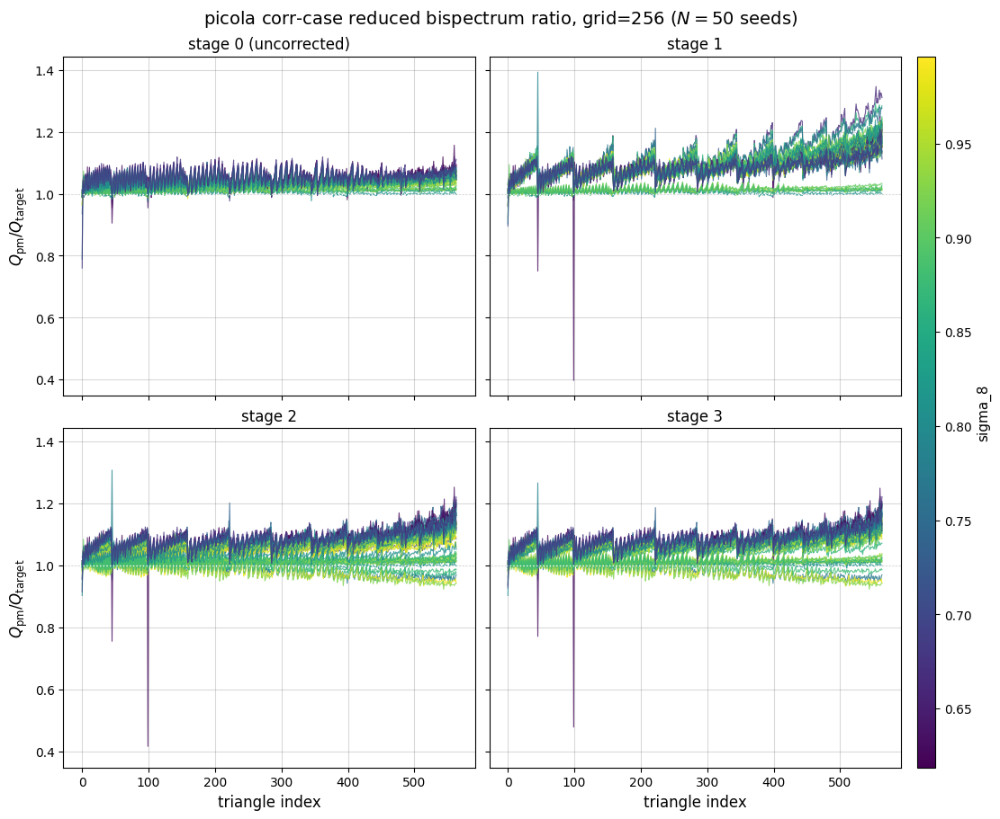

In [83]:
kbm = 0.3
kmm = 0.04
#fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=256,color_by="sigma_8", cosmo_params=cosmo_params, k_max = kbm)
fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=256,color_by="sigma_8", cosmo_params=cosmo_params, k_max = kbm, k_min = kmm, early_stop=True, figroot=os.path.join(basedir, "FASTPM"))

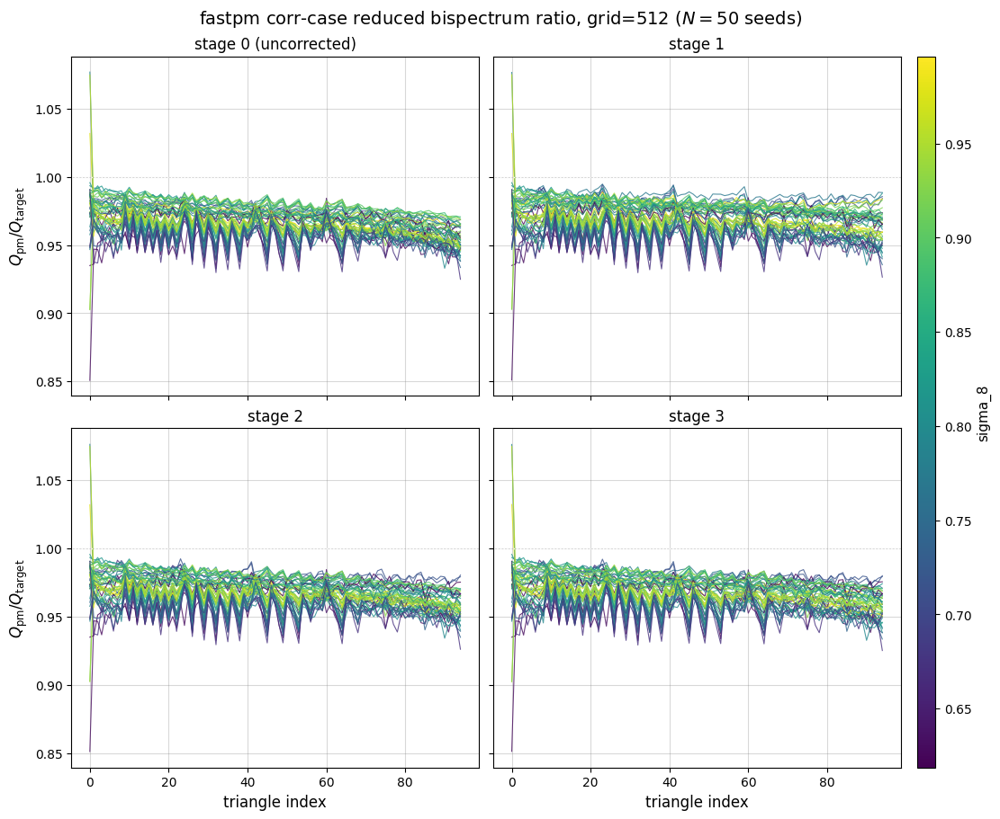

In [85]:
#fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "fastpm", grid=256, color_by="sigma_8", cosmo_params=cosmo_params,k_max = kbm)
kbm = 0.3
kmm = 0.02
fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "fastpm", grid=512,color_by="sigma_8", cosmo_params=cosmo_params, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "FASTPM"))

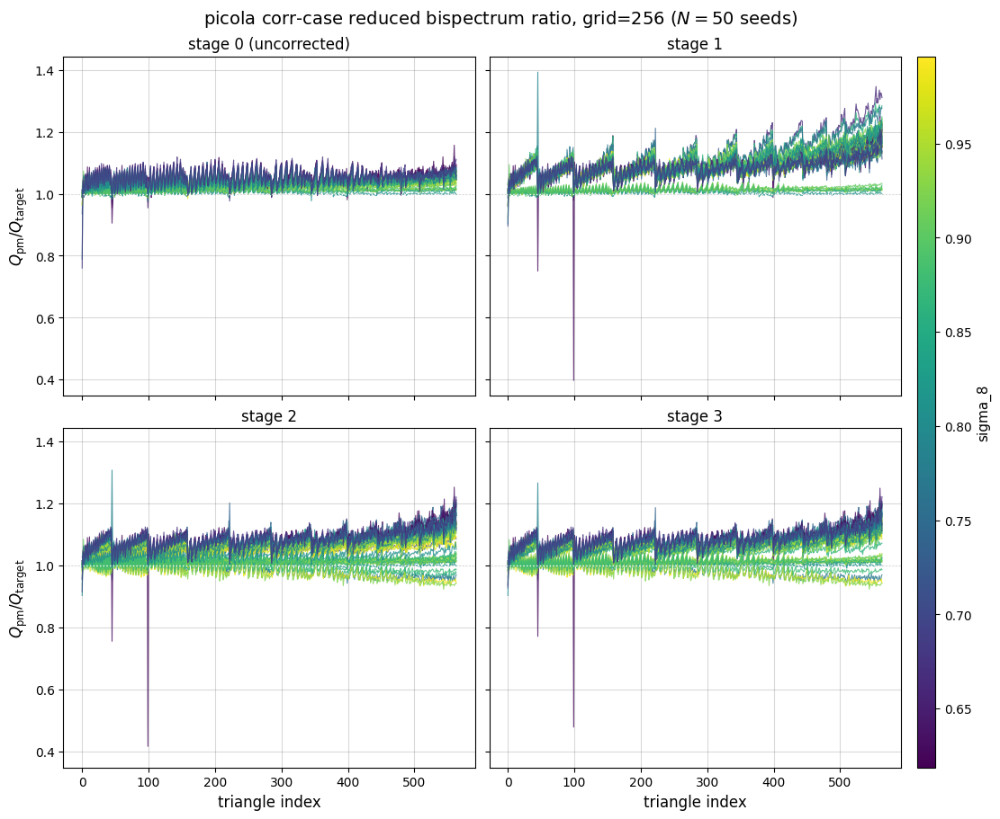

In [88]:
#fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=512,color_by="sigma_8", cosmo_params=cosmo_params,k_max = kbm)
kbm = 0.3
kmm = 0.04
fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=256,color_by="sigma_8", cosmo_params=cosmo_params, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "PICOLA"))

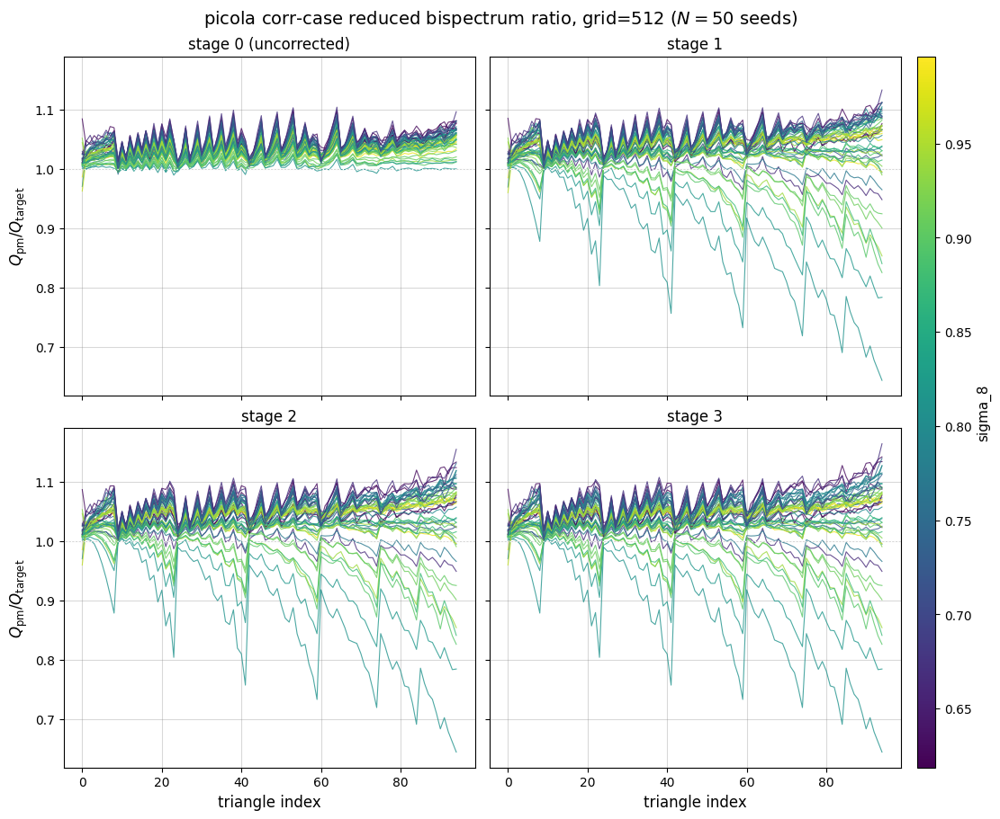

In [89]:
#fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "fastpm", grid=512,color_by="sigma_8", cosmo_params=cosmo_params,k_max = kbm)
kbm = 0.3
kmm = 0.02
fig, axes = plot_bk_ratio_grid_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=512,color_by="sigma_8", cosmo_params=cosmo_params, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "PICOLA"))

In [92]:
def plot_Qk_ratio_envelope_corr(corr_root, qroot, quijote_root, sim, grid, n_seeds=50,
                                  figroot=None, k_min=None, k_max=None,
                                  stages=("pm", "1", "2", "3"),
                                  labels=("stage 0 (uncorrected)", "stage 1", "stage 2", "stage 3"),
                                  colors=("tab:red", "tab:orange", "tab:green", "tab:blue"),
                                  early_stop=False):
    
    fig, ax = plt.subplots(figsize=(9, 7))

    for stage, label, color in zip(stages, labels, colors):
        ratios = []
        n_tri = None
        for seed in range(n_seeds):
            try:
                ratio = load_bk_ratio_corr(corr_root, qroot, quijote_root, sim, seed, stage, grid,
                                            k_min=k_min, k_max=k_max, early_stop=early_stop)
            except FileNotFoundError:
                continue
            n_tri = len(ratio) if n_tri is None else min(n_tri, len(ratio))
            ratios.append(ratio)
        ratios = np.stack([r[:n_tri] for r in ratios])
        lo, hi = ratios.min(axis=0), ratios.max(axis=0)
        x = np.arange(n_tri)
        ax.plot(x, lo, color=color, lw=1.2, ls="--", label=label)
        ax.plot(x, hi, color=color, lw=1.2, ls="--")

    ax.axhline(1.0, color="grey", lw=1, ls=":")
    ax.set_xlabel("triangle index", fontsize=12)
    ax.set_ylabel(r"$Q_\mathrm{pm}/Q_\mathrm{target}$", fontsize=12)
    ax.set_title(f"{sim} corr-case reduced bispectrum ratio, grid={grid} "
                 f"($N={n_seeds}$ seeds, min/max envelope)", fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(color="grey", alpha=0.3)
    plt.tight_layout()
    stages_tag = "_".join(stages)
    if figroot is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, f"Qk_ratio_envelope_corr_{sim}_grid{grid}_{stages_tag}.pdf"),
                     bbox_inches="tight")
    return fig, ax

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'picola corr-case reduced bispectrum ratio, grid=512 ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

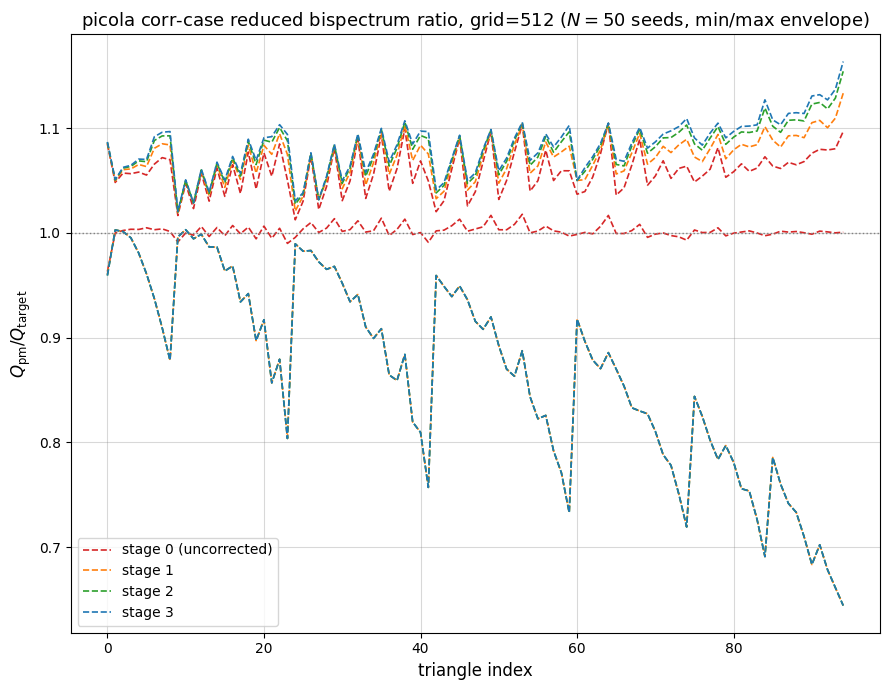

In [93]:
plot_Qk_ratio_envelope_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=512, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "PICOLA"))

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'picola corr-case reduced bispectrum ratio, grid=256 ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

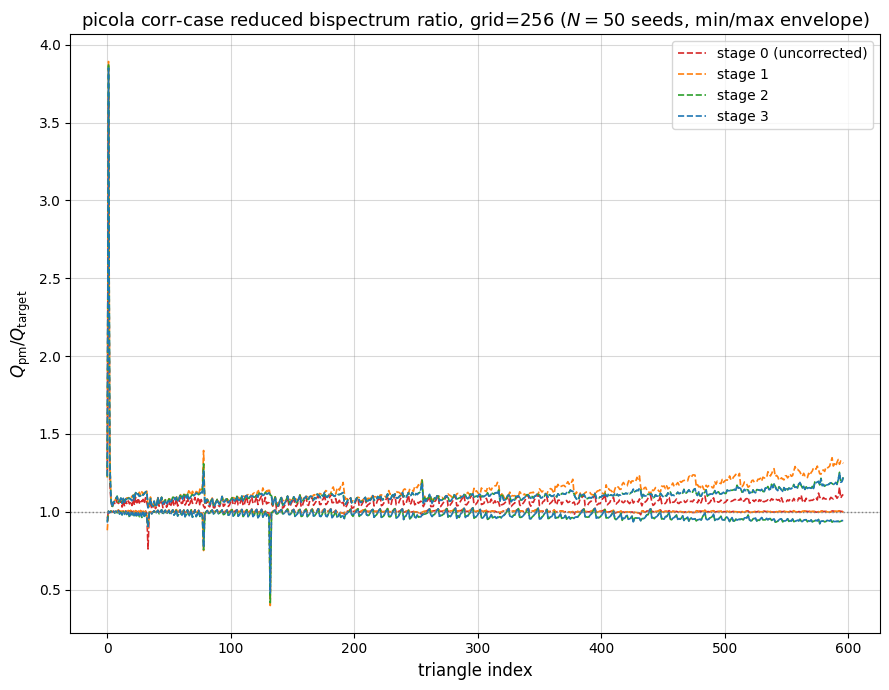

In [94]:
plot_Qk_ratio_envelope_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "picola", grid=256, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "PICOLA"))

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'fastpm corr-case reduced bispectrum ratio, grid=256 ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

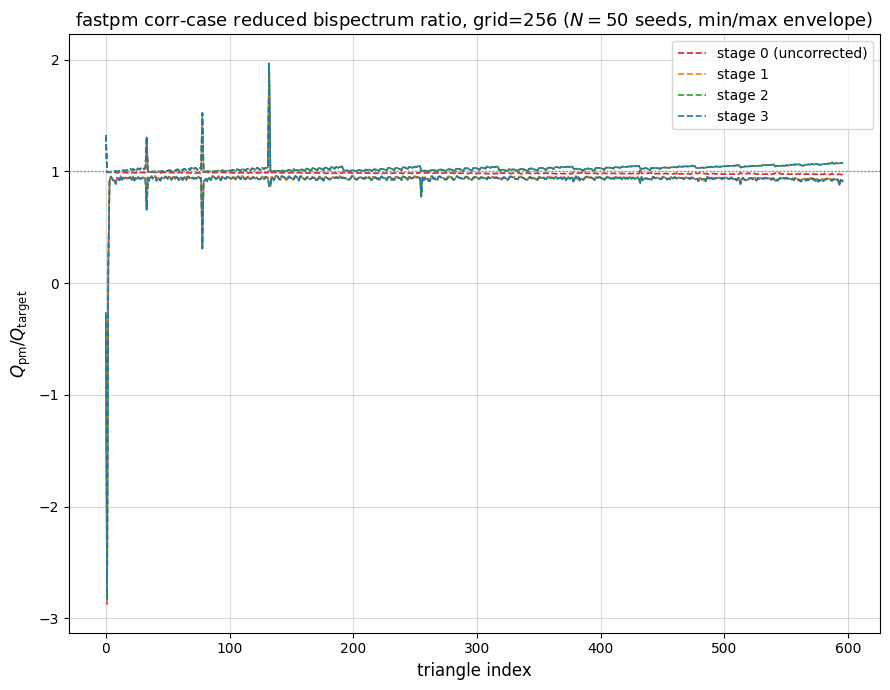

In [95]:
plot_Qk_ratio_envelope_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "fastpm", grid=256, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "FASTPM"))

(<Figure size 900x700 with 1 Axes>,
 <Axes: title={'center': 'fastpm corr-case reduced bispectrum ratio, grid=512 ($N=50$ seeds, min/max envelope)'}, xlabel='triangle index', ylabel='$Q_\\mathrm{pm}/Q_\\mathrm{target}$'>)

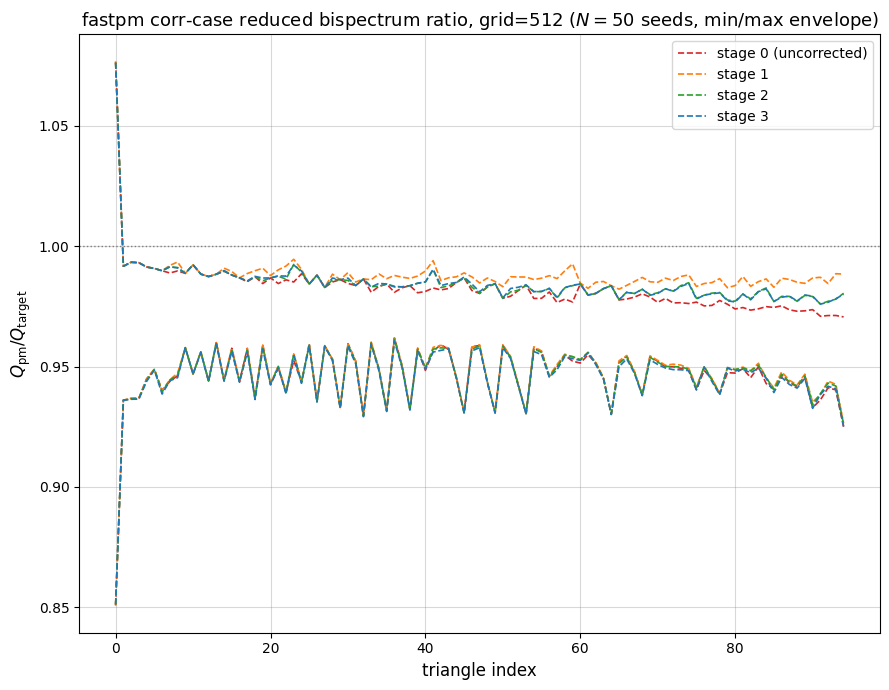

In [96]:
plot_Qk_ratio_envelope_corr(CORR_ROOT, QROOT, QUIJOTE_ROOT, "fastpm", grid=512, k_max = kbm, k_min = kmm, early_stop=True,figroot=os.path.join(basedir, "FASTPM"))

pk_pm_all shape: (50, 48)
0 near-duplicate pairs out of 1225 total pairs
mean CV across k: 0.3986480760232067  min/max CV: 0.3098644430516299 1.5141515691439211


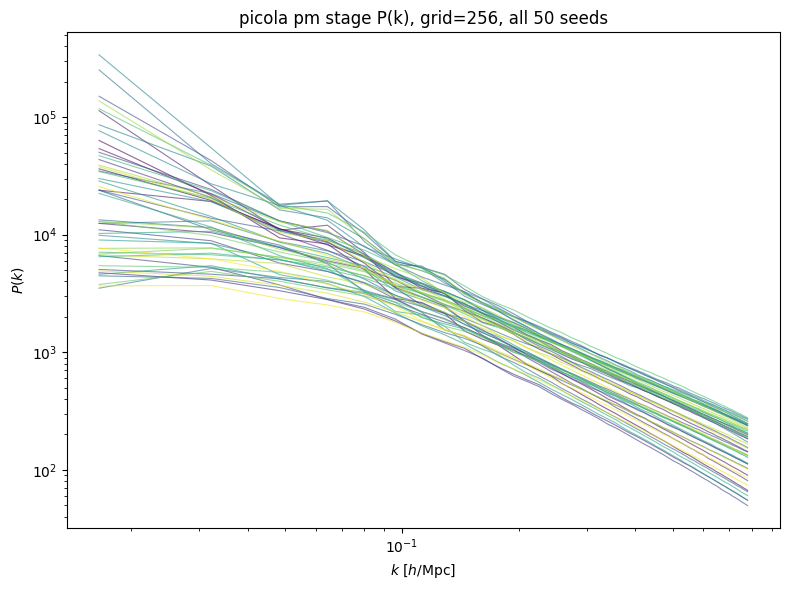

In [91]:
# Pk check pm
def load_all_pm_pk(qroot, sim, grid, n_seeds=50):
    pks = []
    k_ref = None
    for seed in range(n_seeds):
        d = os.path.join(qroot, sim, "seed%d" % seed)
        k = np.load(os.path.join(d, f"k_pm_grid{grid}.npy"))
        pk = np.load(os.path.join(d, f"pk_pm_grid{grid}.npy"))
        if k_ref is None:
            k_ref = k
        pks.append(pk)
    return k_ref, np.stack(pks)

sim, grid = "picola", 256
k_pm, pk_pm_all = load_all_pm_pk(QROOT, sim, grid, n_seeds=50)
print("pk_pm_all shape:", pk_pm_all.shape)

# Direct check: any two seeds suspiciously identical?
n_dupes = 0
for i in range(50):
    for j in range(i + 1, 50):
        if np.allclose(pk_pm_all[i], pk_pm_all[j], rtol=1e-6):
            print(f"seeds {i} and {j} have nearly identical P(k)!")
            n_dupes += 1
print(f"{n_dupes} near-duplicate pairs out of {50*49//2} total pairs")

# Visual check
fig, ax = plt.subplots(figsize=(8, 6))
for seed in range(50):
    ax.plot(k_pm, pk_pm_all[seed], color=plt.cm.viridis(seed / 49), alpha=0.6, lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$"); ax.set_ylabel(r"$P(k)$")
ax.set_title(f"{sim} pm stage P(k), grid={grid}, all 50 seeds")
plt.tight_layout()

# Quantitative spread: coefficient of variation per k-bin
mean_pk = pk_pm_all.mean(axis=0)
std_pk = pk_pm_all.std(axis=0)
cv = std_pk / mean_pk
print("mean CV across k:", cv.mean(), " min/max CV:", cv.min(), cv.max())


In [44]:
import os, time

d = os.path.join(CORR_ROOT, "picola")
rows = []
for seed in range(50):
    f = os.path.join(d, "seed%d" % seed, "pk_corrected_it3_grid256.npy")
    if os.path.exists(f):
        mtime = os.path.getmtime(f)
        rows.append((seed, mtime))

rows.sort(key=lambda r: r[1])
for seed, mtime in rows:
    print(seed, time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(mtime)))


0 2026-10-01 05:54:48
2 2026-10-01 05:55:51
3 2026-10-01 06:00:35
1 2026-10-01 06:01:33
4 2026-10-01 06:03:07
5 2026-10-01 06:03:55
6 2026-10-01 06:05:02
7 2026-10-01 06:10:36
9 2026-10-01 06:12:24
8 2026-10-01 06:12:29
11 2026-10-01 06:15:21
10 2026-10-01 06:15:40
12 2026-10-01 06:17:45
13 2026-10-01 06:18:48
14 2026-10-01 06:19:00
16 2026-10-01 06:27:28
15 2026-10-01 06:27:47
17 2026-10-01 06:50:30
18 2026-10-01 07:49:24
19 2026-10-01 08:38:28
20 2026-10-01 08:40:32
21 2026-10-01 08:54:09
22 2026-10-01 08:55:53
23 2026-10-01 09:07:01
24 2026-10-01 09:09:14
25 2026-10-01 09:10:34
26 2026-10-01 09:22:18
27 2026-10-01 09:24:17
28 2026-10-01 09:25:17
29 2026-10-01 09:38:12
30 2026-10-01 09:38:59
31 2026-10-01 09:39:49
32 2026-10-01 09:52:32
33 2026-10-01 09:53:47
34 2026-10-01 09:54:09
35 2026-10-01 09:54:44
36 2026-10-01 10:25:18
37 2026-10-01 10:26:53
38 2026-10-01 10:51:42
39 2026-10-01 11:08:44
40 2026-10-01 11:24:13
42 2026-10-01 11:33:33
41 2026-10-01 11:33:41
43 2026-10-01 11:34:3

In [42]:
import os, time, argparse
import numpy as np
from pmesh.pm import ParticleMesh
from pypower import MeshFFTPower


def measure_power_from_mesh(delta, BoxSize, kedges):
    grid = delta.shape[0]
    pm = ParticleMesh(BoxSize=[BoxSize] * 3, Nmesh=[grid] * 3, dtype='f8')
    field = pm.create(type='real')
    field[...] = delta

    result = MeshFFTPower(field, edges=kedges, ells=(0,))
    poles = result.poles
    k, Pk = poles(ell=0, return_k=True, complex=False)
    mask = ~np.isnan(k) & ~np.isnan(Pk)
    return k[mask], Pk[mask]


def run_seed(seed, grid, quijote_root):
    outdir = os.path.join(quijote_root, str(seed))
    k_path = os.path.join(outdir, "k_grid%d.npy" % grid)
    if os.path.exists(k_path):
        print(f"[seed {seed}] already complete, skipping")
        return

    BoxSize = 1000.0
    delta = np.load(os.path.join(outdir, "delta_grid%d.npy" % grid))

    kFund = 2 * np.pi / BoxSize
    kNyquist = np.pi * grid / BoxSize
    num_bins = 50
    kedges = np.linspace(kFund, kNyquist, num_bins)[:-1]

    start = time.time()
    k, Pk = measure_power_from_mesh(delta, BoxSize, kedges)
    np.save(k_path, k)
    np.save(os.path.join(outdir, "pk_grid%d.npy" % grid), Pk)
    print(f"[seed {seed}] done in {time.time()-start:.1f}s")




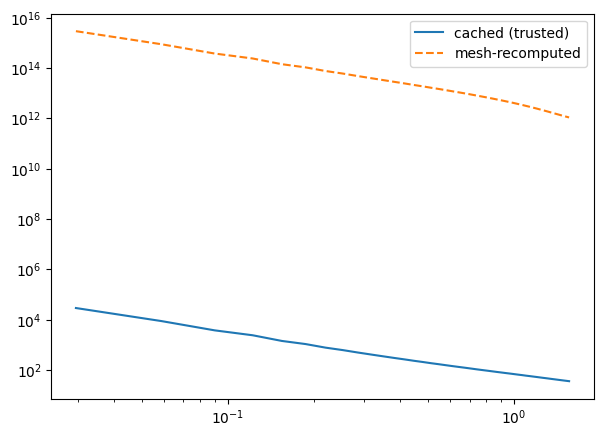

In [43]:
# sanity check: does this method reproduce the already-trusted k.npy/pk.npy at grid=512?
test_seed = 0
d = os.path.join(QUIJOTE_ROOT, str(test_seed))
delta_512 = np.load(os.path.join(d, "delta_grid512.npy"))
BoxSize = 1000.0
kFund = 2 * np.pi / BoxSize
kNyquist = np.pi * 512 / BoxSize
kedges_512 = np.linspace(kFund, kNyquist, 50)[:-1]

k_test, pk_test = measure_power_from_mesh(delta_512, BoxSize, kedges_512)
k_trusted = np.load(os.path.join(d, "k.npy"))
pk_trusted = np.load(os.path.join(d, "pk.npy"))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(k_trusted, pk_trusted, label="cached (trusted)")
ax.plot(k_test, pk_test, '--', label="mesh-recomputed")
ax.set_xscale("log"); ax.set_yscale("log")
ax.legend()


In [26]:
import os
d_corr = os.path.join(CORR_ROOT, "picola", "seed0")
d_q = os.path.join(QROOT, "picola", "seed0")

link_path = os.path.join(d_corr, "k_pm_grid256.npy")
print("is symlink:", os.path.islink(link_path))
print("resolves to:", os.path.realpath(link_path))
print("target exists:", os.path.exists(os.path.realpath(link_path)))

k_via_corr = np.load(link_path)
k_via_q = np.load(os.path.join(d_q, "k_pm_grid256.npy"))
print("match:", np.array_equal(k_via_corr, k_via_q))


is symlink: True
resolves to: /work/hdd/bdne/nchartier/Q_correction/picola/seed0/k_pm_grid256.npy
target exists: True
match: True


k match: True
pk match: True


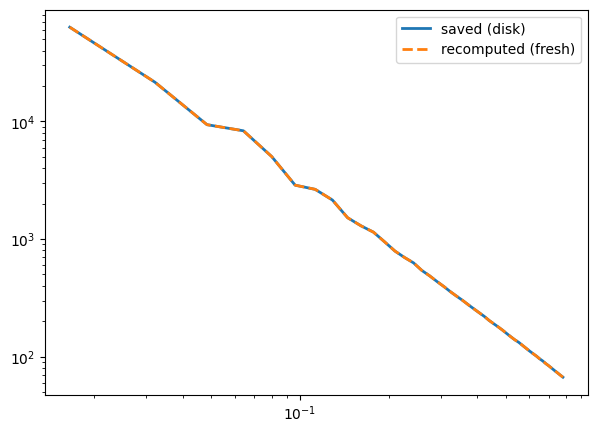

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
import readgadget
from pypower import CatalogFFTPower

BoxSize = 1000.0   # fixed for all Quijote LH realizations

def measure_power_pypower(positions, BoxSize, grid, kedges, resampler='cic',
                           interlacing=2, dtype='f4', ells=(0,),
                           remove_shotnoise=True, position_type='pos'):
    result = CatalogFFTPower(data_positions1=positions, boxsize=BoxSize, nmesh=grid,
                              resampler=resampler, edges=kedges, ells=ells,
                              interlacing=interlacing, position_type=position_type,
                              dtype=dtype)
    poles = result.poles
    k, Pk = poles(ell=ells[0], return_k=True, complex=False, remove_shotnoise=remove_shotnoise)
    mask = ~np.isnan(k) & ~np.isnan(Pk)
    return k[mask], Pk[mask]

QROOT = "/work/hdd/bdne/nchartier/Q_correction"
CORR_ROOT = "/work/hdd/bdne/nchartier/Corr_correction"

test_seed = 0
d_q = os.path.join(QROOT, "picola", "seed%d" % test_seed)

path = "/work/hdd/bdne/nchartier/cola_lh/%d/Cola%d_512_20stepsnLPTpos0p5_z0p500" % (test_seed, test_seed)
pos_pm_test = readgadget.read_block(path, "POS ", [1]) / 1e3

kFund = 2 * np.pi / BoxSize
kNyquist = np.pi * 256 / BoxSize
kedges_256 = np.linspace(kFund, kNyquist, 50)[:-1]
k_fresh, pk_fresh = measure_power_pypower(pos_pm_test, BoxSize, 256, kedges_256)

k_saved = np.load(os.path.join(d_q, "k_pm_grid256.npy"))
pk_saved = np.load(os.path.join(d_q, "pk_pm_grid256.npy"))

print("k match:", np.allclose(k_saved, k_fresh, rtol=1e-3))
print("pk match:", np.allclose(pk_saved, pk_fresh, rtol=1e-2))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(k_saved, pk_saved, label="saved (disk)", lw=2)
ax.plot(k_fresh, pk_fresh, '--', label="recomputed (fresh)", lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.legend()



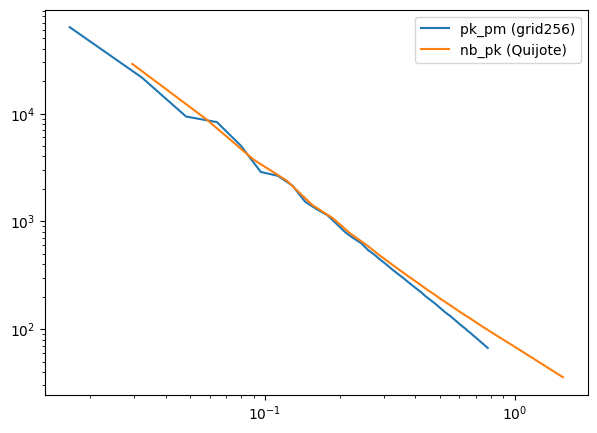

In [35]:
k_nb_ = np.load(os.path.join(CORR_ROOT, "picola", "seed0", "nb_k.npy"))
pk_nb_ = np.load(os.path.join(CORR_ROOT, "picola", "seed0", "nb_pk.npy"))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(k_saved, pk_saved, label="pk_pm (grid256)")
ax.plot(k_nb_, pk_nb_, label="nb_pk (Quijote)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.legend()


In [36]:
print("k_saved (pk_pm, grid256) first 3:", k_saved[:3])
print("k_nb_   (Quijote) first 3:        ", k_nb_[:3])
print("kFund (theoretical):", 2 * np.pi / BoxSize)


k_saved (pk_pm, grid256) first 3: [0.01653494 0.03219333 0.04832578]
k_nb_   (Quijote) first 3:         [0.02946079 0.05858095 0.09006009]
kFund (theoretical): 0.006283185307179587


In [37]:
print("len(k_saved):", len(k_saved), "  len(k_nb_):", len(k_nb_))
print("k_nb_ spacing (first few):", np.diff(k_nb_[:5]))
print("k_saved spacing (first few):", np.diff(k_saved[:5]))


len(k_saved): 48   len(k_nb_): 48
k_nb_ spacing (first few): [0.02912016 0.03147914 0.03214591 0.03239648]
k_saved spacing (first few): [0.01565839 0.01613245 0.01591229 0.01589094]


# Trying PQMass, Q corrections

## 2d tests

## 3d tests 30/09/2026

In [34]:
import json
PQM_OUTROOT = "/work/hdd/bdne/nchartier/PQMass_results"
sims, cases, which_bs, grid = ("picola", "fastpm"), ("raw", "octant"), ("1", "3", "pm"), 256

print(f"{'sim':8} {'case':8} {'stage':6} {'#warn':>6}  sample warning")
for sim in sims:
    for case in cases:
        for which_b in which_bs:
            path = os.path.join(PQM_OUTROOT, f"pqm_{case}_{sim}_nb_vs_{which_b}_grid{grid}.json")
            result = json.load(open(path))
            warns = result.get("warnings", [])
            sample = warns[0][:80].replace("\n", " ") if warns else ""
            print(f"{sim:8} {case:8} {which_b:6} {len(warns):6}  {sample}")

sim      case     stage   #warn  sample warning
picola   raw      1         337               Less than half of the Voronoi cells have any samples in them.      
picola   raw      3         355               Less than half of the Voronoi cells have any samples in them.      
picola   raw      pm        315               Less than half of the Voronoi cells have any samples in them.      
picola   octant   1           0  
picola   octant   3           0  
picola   octant   pm          0  
fastpm   raw      1         352               Less than half of the Voronoi cells have any samples in them.      
fastpm   raw      3         342               Less than half of the Voronoi cells have any samples in them.      
fastpm   raw      pm        362               Less than half of the Voronoi cells have any samples in them.      
fastpm   octant   1           0  
fastpm   octant   3           0  
fastpm   octant   pm          0  


In [55]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2 as chi2_dist

PQM_OUTROOT = "/work/hdd/bdne/nchartier/PQMass_results"
GRID = 256
NUM_REFS = 50


def load_pqm_result(path):
    with open(path) as f:
        return json.load(f)

def pqm_signal_path(sim, which_b, grid=GRID, znorm=False, case="octant"):
    tag = "_znorm" if znorm else ""
    return os.path.join(PQM_OUTROOT, f"pqm_{case}_{sim}_nb500_vs_{which_b}_grid{grid}{tag}.json")


def pqm_null_path(grid=GRID, znorm=False, case="octant"):
    tag = "_znorm" if znorm else ""
    return os.path.join(PQM_OUTROOT, f"pqm_{case}_quijote_null_grid{grid}{tag}.json")




def summarize_pqm_results(sims=("picola", "fastpm"), which_bs=("pm", "1", "3"), grid=GRID,
                            znorm=False, case="octant"):
    rows = [("quijote_null", "-", pqm_null_path(grid, znorm, case))]
    for sim in sims:
        for which_b in which_bs:
            rows.append((sim, which_b, pqm_signal_path(sim, which_b, grid, znorm, case)))

    print(f"{'case':14} {'stage':6} {'status':8} {'chi2_mean':>10} {'pval_mean':>10} {'empty_frac':>10}")
    results = {}
    for sim, which_b, path in rows:
        key = (sim, which_b)
        if not os.path.exists(path):
            print(f"{sim:14} {which_b:6} {'MISSING':8}")
            results[key] = None
            continue
        r = load_pqm_result(path)
        results[key] = r
        if r.get("failed"):
            print(f"{sim:14} {which_b:6} {'FAILED':8} ({r.get('error', '')[:40].strip()})")
        else:
            ef = r.get("empty_frac", float('nan'))
            print(f"{sim:14} {which_b:6} {'OK':8} {r['chi2_mean']:10.2f} {r['pval_mean']:10.4g} {ef:10.2%}")
    return results





def plot_pqm_ood_panels(panels, num_refs=NUM_REFS, sim_label="", figroot=None, fname=None):
    '''One histogram panel per (label, chi2_array), theoretical chi2(dof) curve (black)
    identical on every panel, dof = num_refs - 1.'''
    dof = num_refs - 1
    fig, axes = plt.subplots(ncols=len(panels), figsize=(4.2 * len(panels), 4), sharey=True)
    if len(panels) == 1:
        axes = [axes]

    nonempty = [np.asarray(v) for _, v in panels if len(v) > 0]
    x_max = max(max(a.max() for a in nonempty), chi2_dist.ppf(0.999, dof)) * 1.05 if nonempty else chi2_dist.ppf(0.999, dof) * 1.05
    x = np.linspace(0, x_max, 500)
    theory_pdf = chi2_dist.pdf(x, dof)
    theory_mean, theory_std = dof, np.sqrt(2 * dof)

    for ax, (label, chi2_arr) in zip(axes, panels):
        chi2_arr = np.asarray(chi2_arr)
        if len(chi2_arr) > 0:
            ax.hist(chi2_arr, bins=25, density=True, color="cyan", alpha=0.6, edgecolor="none")
            ax.text(0.97, 0.88, r"$%.2f \pm %.2f$" % (chi2_arr.mean(), chi2_arr.std()),
                    transform=ax.transAxes, ha="right", va="top", color="darkcyan", fontsize=9)
        ax.plot(x, theory_pdf, color="black", lw=1.8)
        ax.set_title(label, fontsize=12)
        ax.set_xlabel(r"$\chi^2_\mathrm{PQM}$", fontsize=11)
        ax.text(0.97, 0.95, r"$%d \pm %.2f$" % (theory_mean, theory_std),
                transform=ax.transAxes, ha="right", va="top", color="black", fontsize=9)
        ax.grid(color="grey", alpha=0.3)

    axes[0].set_ylabel("Frequency (density)", fontsize=11)
    fig.suptitle(r"PQMass field-level OOD test — %s" % sim_label, fontsize=14)
    plt.tight_layout()
    if figroot is not None and fname is not None:
        os.makedirs(figroot, exist_ok=True)
        plt.savefig(os.path.join(figroot, fname), bbox_inches="tight")
    return fig, axes

def plot_pqm_figure3_style(sim, which_bs=("pm", "1", "3"), grid=GRID, figroot=None, prefix="",
                             znorm=False, case="octant"):
    null_result = load_pqm_result(pqm_null_path(grid, znorm, case))
    chi2_null = np.asarray(null_result.get("chi2_list", []))

    panels = [("Quijote LH", chi2_null)]
    for which_b in which_bs:
        r = load_pqm_result(pqm_signal_path(sim, which_b, grid, znorm, case))
        label = f"{sim} {prefix} stage 0" if which_b == "pm" else f"{sim} {prefix} stage {which_b}"
        panels.append((label, np.asarray(r.get("chi2_list", []))))

    znorm_tag = "_znorm" if znorm else ""
    fname = f"pqm_ood_panels_{sim}_{case}_500ref{znorm_tag}.pdf" if figroot else None
    return plot_pqm_ood_panels(panels, num_refs=NUM_REFS, sim_label=sim,
                                figroot=figroot, fname=fname)



In [56]:
_ = summarize_pqm_results(znorm=True, case = "octant")


case           stage  status    chi2_mean  pval_mean empty_frac
quijote_null   -      OK            49.42     0.5082     51.70%
picola         pm     OK           128.46   0.001417      0.10%
picola         1      OK           127.39  0.0002063      0.80%
picola         3      OK           128.02   0.002144      0.40%
fastpm         pm     OK           128.07   0.001232      0.20%
fastpm         1      OK           127.10   0.002448      0.40%
fastpm         3      OK           129.42   0.001023      0.40%


In [57]:
_ = summarize_pqm_results(znorm=True, case = "2dslice")

case           stage  status    chi2_mean  pval_mean empty_frac
quijote_null   -      OK            49.96     0.4928     17.70%
picola         pm     OK           118.89   0.002046      0.10%
picola         1      OK           119.30   0.005591      0.10%
picola         3      OK           119.06   0.003782      0.00%
fastpm         pm     OK           118.25   0.002469      0.20%
fastpm         1      OK           119.35   0.003316      0.00%
fastpm         3      OK           120.52   0.001945      0.00%


(<Figure size 1680x400 with 4 Axes>,
 array([<Axes: title={'center': 'Quijote LH'}, xlabel='$\\chi^2_\\mathrm{PQM}$', ylabel='Frequency (density)'>,
        <Axes: title={'center': 'fastpm Q stage 0'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'fastpm Q stage 1'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'fastpm Q stage 3'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>],
       dtype=object))

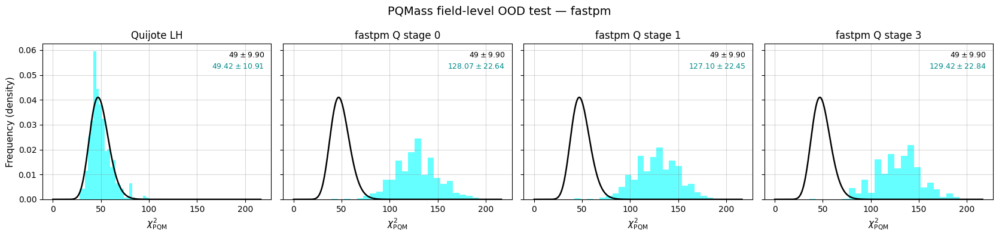

In [61]:
plot_pqm_figure3_style("fastpm", prefix = "Q", znorm=True, case = "octant")

(<Figure size 1680x400 with 4 Axes>,
 array([<Axes: title={'center': 'Quijote LH'}, xlabel='$\\chi^2_\\mathrm{PQM}$', ylabel='Frequency (density)'>,
        <Axes: title={'center': 'picola Q stage 0'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'picola Q stage 1'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'picola Q stage 3'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>],
       dtype=object))

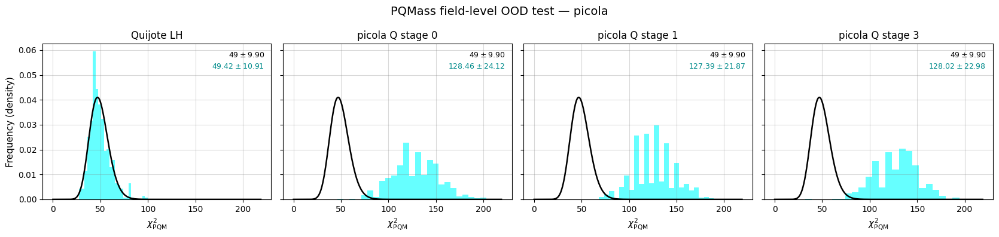

In [62]:
plot_pqm_figure3_style("picola",znorm=True, prefix = "Q", case = "octant")

(<Figure size 1680x400 with 4 Axes>,
 array([<Axes: title={'center': 'Quijote LH'}, xlabel='$\\chi^2_\\mathrm{PQM}$', ylabel='Frequency (density)'>,
        <Axes: title={'center': 'fastpm Q stage 0'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'fastpm Q stage 1'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'fastpm Q stage 3'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>],
       dtype=object))

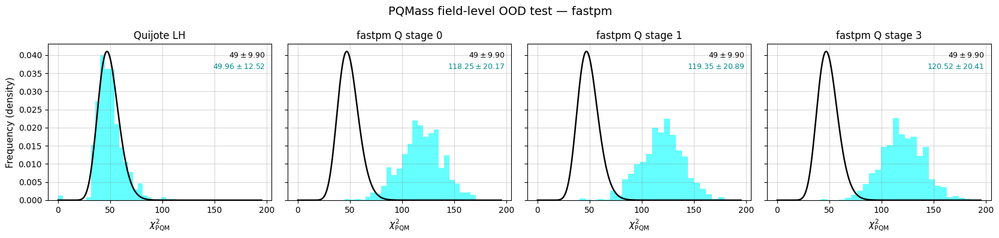

In [63]:
plot_pqm_figure3_style("fastpm", prefix = "Q", znorm=True, case = "2dslice")

(<Figure size 1680x400 with 4 Axes>,
 array([<Axes: title={'center': 'Quijote LH'}, xlabel='$\\chi^2_\\mathrm{PQM}$', ylabel='Frequency (density)'>,
        <Axes: title={'center': 'picola Q stage 0'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'picola Q stage 1'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>,
        <Axes: title={'center': 'picola Q stage 3'}, xlabel='$\\chi^2_\\mathrm{PQM}$'>],
       dtype=object))

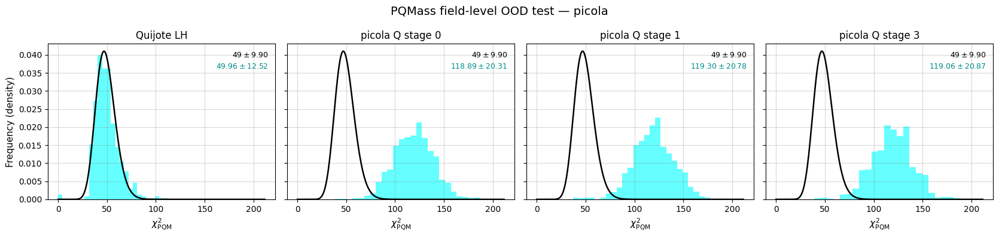

In [ ]:
plot_pqm_figure3_style("picola",znorm=True, prefix = "Q", case = "2dslice")